# **Analyse des données de systèmes éducatifs**

## **Problématique**

Déterminer dans quels pays il serait le plus judicieux de développer une école de e-learning pour des élèves de niveau bac ou universitaires.  
Pour notre étude nous utiliserons la base de données consacrée à l’éducation EdStatsData de La banque mondiale, ainsi que quelques outils complémentaires.


**Méthodologie :**
- Présentation de données
- Cadrage de l’étude
- Nettoyage des données
- Analyse

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
EdStatsCountry = pd.read_csv("EdStatsCountry.csv")
EdStatsData = pd.read_csv("EdStatsData.csv")
EdStatsSeries = pd.read_csv("EdStatsSeries.csv")
EdStatsCountry_Series = pd.read_csv("EdStatsCountry-Series.csv")
EdStatsFootNote = pd.read_csv("EdStatsFootNote.csv")

## **Présentation des données**

### EdStatsCountry

In [2]:
EdStatsCountry.head()

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data,Unnamed: 31
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from offici...,Latin America & Caribbean,High income: nonOECD,AW,...,NaN,2010,NaN,NaN,Yes,NaN,NaN,2012.0,NaN,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period fo...,South Asia,Low income,AF,...,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2012.0,2000,NaN
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data,...",Sub-Saharan Africa,Upper middle income,AO,...,General Data Dissemination System (GDDS),1970,"Malaria Indicator Survey (MIS), 2011","Integrated household survey (IHS), 2008",NaN,2015,NaN,NaN,2005,NaN
3,ALB,Albania,Albania,Republic of Albania,AL,Albanian lek,NaN,Europe & Central Asia,Upper middle income,AL,...,General Data Dissemination System (GDDS),2011,"Demographic and Health Survey (DHS), 2008/09",Living Standards Measurement Study Survey (LSM...,Yes,2012,2010.0,2012.0,2006,NaN
4,AND,Andorra,Andorra,Principality of Andorra,AD,Euro,NaN,Europe & Central Asia,High income: nonOECD,AD,...,NaN,2011. Population figures compiled from adminis...,NaN,NaN,Yes,NaN,NaN,2006.0,NaN,NaN


In [3]:
EdStatsCountry.info()

<class 'pandas.DataFrame'>
RangeIndex: 241 entries, 0 to 240
Data columns (total 32 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Country Code                                       241 non-null    str    
 1   Short Name                                         241 non-null    str    
 2   Table Name                                         241 non-null    str    
 3   Long Name                                          241 non-null    str    
 4   2-alpha code                                       238 non-null    str    
 5   Currency Unit                                      215 non-null    str    
 6   Special Notes                                      145 non-null    str    
 7   Region                                             214 non-null    str    
 8   Income Group                                       214 non-null    str    
 9   WB-2 code            

EdStatsCountry possède 241 lignes et 32 colonnes.

In [4]:
EdStatsCountry.nunique()

Country Code                                         241
Short Name                                           241
Table Name                                           241
Long Name                                            241
2-alpha code                                         238
Currency Unit                                        152
Special Notes                                        131
Region                                                 7
Income Group                                           5
WB-2 code                                            240
National accounts base year                           43
National accounts reference year                      11
SNA price valuation                                    2
Lending category                                       3
Other groups                                           2
System of National Accounts                            3
Alternative conversion factor                         32
PPP survey year                

On constate qu'il y a 241 noms de pays, donc chaque ligne de ce tableau correspond à un pays, et les colonnes donnent divers informations sur le pays en question.

Faisons apparaitre les eventuels doublons de ce tableau.

In [5]:
EdStatsCountry[EdStatsCountry.duplicated(keep=False)]

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data,Unnamed: 31


Il n'y a pas de doublons.

In [6]:
Country = EdStatsCountry.drop("Unnamed: 31", axis = 1)
Country.head(1)

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from offici...,Latin America & Caribbean,High income: nonOECD,AW,...,NaN,NaN,2010,NaN,NaN,Yes,NaN,NaN,2012.0,NaN


### EdStatSeries

In [7]:
EdStatsSeries.head()

,Series Code,Topic,Indicator Name,Short definition,Long definition,Unit of measure,Periodicity,Base Period,Other notes,Aggregation method,...,Notes from original source,General comments,Source,Statistical concept and methodology,Development relevance,Related source links,Other web links,Related indicators,License Type,Unnamed: 20
0,BAR.NOED.1519.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 15-19 with...,Percentage of female population age 15-19 with...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BAR.NOED.1519.ZS,Attainment,Barro-Lee: Percentage of population age 15-19 ...,Percentage of population age 15-19 with no edu...,Percentage of population age 15-19 with no edu...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,BAR.NOED.15UP.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 15+ with n...,Percentage of female population age 15+ with n...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,BAR.NOED.15UP.ZS,Attainment,Barro-Lee: Percentage of population age 15+ wi...,Percentage of population age 15+ with no educa...,Percentage of population age 15+ with no educa...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,BAR.NOED.2024.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 20-24 with...,Percentage of female population age 20-24 with...,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
EdStatsSeries.info()

<class 'pandas.DataFrame'>
RangeIndex: 3665 entries, 0 to 3664
Data columns (total 21 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Series Code                          3665 non-null   str    
 1   Topic                                3665 non-null   str    
 2   Indicator Name                       3665 non-null   str    
 3   Short definition                     2156 non-null   str    
 4   Long definition                      3665 non-null   str    
 5   Unit of measure                      0 non-null      float64
 6   Periodicity                          99 non-null     str    
 7   Base Period                          314 non-null    str    
 8   Other notes                          552 non-null    str    
 9   Aggregation method                   47 non-null     str    
 10  Limitations and exceptions           14 non-null     str    
 11  Notes from original source           0 no

EdStatsSeries contient 3665 lignes et 21 colonnes.

In [9]:
EdStatsSeries.nunique()

Series Code                            3665
Topic                                    37
Indicator Name                         3665
Short definition                       1169
Long definition                        2060
Unit of measure                           0
Periodicity                               1
Base Period                               4
Other notes                              14
Aggregation method                        3
Limitations and exceptions                9
Notes from original source                0
General comments                          8
Source                                   31
Statistical concept and methodology       2
Development relevance                     1
Related source links                      1
Other web links                           0
Related indicators                        0
License Type                              0
Unnamed: 20                               0
dtype: int64

Il y a 3665 indicateurs.
Donc chaque ligne correspond a un indicateur, et les colonnes fournissent des informations sur ces indicateurs.

Verifions si il y a des doublons.

In [10]:
EdStatsSeries[EdStatsSeries.duplicated(keep=False)]

,Series Code,Topic,Indicator Name,Short definition,Long definition,Unit of measure,Periodicity,Base Period,Other notes,Aggregation method,...,Notes from original source,General comments,Source,Statistical concept and methodology,Development relevance,Related source links,Other web links,Related indicators,License Type,Unnamed: 20


Il n'y a pas de doublons.

In [11]:
Series = EdStatsSeries.drop("Unnamed: 20", axis = 1)
Series.head(1)

,Series Code,Topic,Indicator Name,Short definition,Long definition,Unit of measure,Periodicity,Base Period,Other notes,Aggregation method,Limitations and exceptions,Notes from original source,General comments,Source,Statistical concept and methodology,Development relevance,Related source links,Other web links,Related indicators,License Type
0,BAR.NOED.1519.FE.ZS,Attainment,Barro-Lee: Percentage of female population age...,Percentage of female population age 15-19 with...,Percentage of female population age 15-19 with...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.b...,NaN,NaN,NaN,NaN,NaN,NaN


### EdStatsData

In [12]:
EdStatsData.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,...,2060,2065,2070,2075,2080,2085,2090,2095,2100,Unnamed: 69
0,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.F,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.GPI,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.M,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Arab World,ARB,"Adjusted net enrolment rate, primary, both sex...",SE.PRM.TENR,54.822121,54.894138,56.209438,57.267109,57.991138,59.36554,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
EdStatsData.info()

<class 'pandas.DataFrame'>
RangeIndex: 886930 entries, 0 to 886929
Data columns (total 70 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Country Name    886930 non-null  str    
 1   Country Code    886930 non-null  str    
 2   Indicator Name  886930 non-null  str    
 3   Indicator Code  886930 non-null  str    
 4   1970            72288 non-null   float64
 5   1971            35537 non-null   float64
 6   1972            35619 non-null   float64
 7   1973            35545 non-null   float64
 8   1974            35730 non-null   float64
 9   1975            87306 non-null   float64
 10  1976            37483 non-null   float64
 11  1977            37574 non-null   float64
 12  1978            37576 non-null   float64
 13  1979            36809 non-null   float64
 14  1980            89122 non-null   float64
 15  1981            38777 non-null   float64
 16  1982            37511 non-null   float64
 17  1983            38460

EdStatsData possède 886930 lignes, et 70 colonnes.
Les quatres premières colonnes sont de types catégorielles et les autres colonnes de type quantitatives.
Les quatres premières colonnes renseigne sur le pays et l'indicateur, et les colonnes suivantes donnent la valeur de cet indicateur pour le pays en question suivant l'année. On a des années renseignées de 1970 à 2100.
De 1970 à 2017 les données sont annuelles, tandis qu'à partir de 2020 elles sont quiquennales. On peut donc penser qu'à partir de 2020 les données renseignées sont des projections futures.
C'est ce Dataframe qui contient les données.

In [14]:
EdStatsData.select_dtypes(include="string").nunique()

Country Name       242
Country Code       242
Indicator Name    3665
Indicator Code    3665
dtype: int64

Chaque ligne correspond donc à un pays et un indicateur.

Regardons si il y a des doublons dans ce tableau.

In [15]:
EdStatsData[EdStatsData.duplicated(keep=False)]

,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,...,2060,2065,2070,2075,2080,2085,2090,2095,2100,Unnamed: 69


Il n'y a pas de doublons.

In [16]:
Data = EdStatsData.drop("Unnamed: 69", axis = 1)
Data.head(1)

,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,...,2055,2060,2065,2070,2075,2080,2085,2090,2095,2100
0,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### EdStatsCountry-Series

In [17]:
pd.set_option("display.max_colwidth", None)
EdStatsCountry_Series.head()

,CountryCode,SeriesCode,DESCRIPTION,Unnamed: 3
0,ABW,SP.POP.TOTL,Data sources : United Nations World Population Prospects,NaN
1,ABW,SP.POP.GROW,Data sources: United Nations World Population Prospects,NaN
2,AFG,SP.POP.GROW,Data sources: United Nations World Population Prospects,NaN
3,AFG,NY.GDP.PCAP.PP.CD,Estimates are based on regression.,NaN
4,AFG,SP.POP.TOTL,Data sources : United Nations World Population Prospects,NaN


Chaque ligne correspond à un indicateur pour un pays donné. Ce tableau donne des precisions sur les sources des données fournies
pour chaque estimateur.

In [18]:
EdStatsCountry_Series.info()

<class 'pandas.DataFrame'>
RangeIndex: 613 entries, 0 to 612
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   CountryCode  613 non-null    str    
 1   SeriesCode   613 non-null    str    
 2   DESCRIPTION  613 non-null    str    
 3   Unnamed: 3   0 non-null      float64
dtypes: float64(1), str(3)
memory usage: 19.3 KB


Ce tableau est constitué de 613 lignes et 3 colonnes.

In [19]:
EdStatsCountry_Series.nunique()

CountryCode    211
SeriesCode      21
DESCRIPTION     97
Unnamed: 3       0
dtype: int64

EdStatsCountry_Series contient 211 pays et 21 indicateurs.

Verifions si il y a des doublons.

In [20]:
EdStatsCountry_Series[EdStatsCountry_Series.duplicated(keep=False)]

,CountryCode,SeriesCode,DESCRIPTION,Unnamed: 3


Il n'y a pas de doublons.

### EdStatsFootnote

In [21]:
EdStatsFootNote.head()

,CountryCode,SeriesCode,Year,DESCRIPTION,Unnamed: 4
0,ABW,SE.PRE.ENRL.FE,YR2001,Country estimation.,NaN
1,ABW,SE.TER.TCHR.FE,YR2005,Country estimation.,NaN
2,ABW,SE.PRE.TCHR.FE,YR2000,Country estimation.,NaN
3,ABW,SE.SEC.ENRL.GC,YR2004,Country estimation.,NaN
4,ABW,SE.PRE.TCHR,YR2006,Country estimation.,NaN


Chaque ligne représente un pays et un indicateur pour une année donnée. Ce tableau donne des précisions sur la manière
dont ont été obtenues les données.

In [22]:
EdStatsFootNote.info()

<class 'pandas.DataFrame'>
RangeIndex: 643638 entries, 0 to 643637
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   CountryCode  643638 non-null  str    
 1   SeriesCode   643638 non-null  str    
 2   Year         643638 non-null  str    
 3   DESCRIPTION  643638 non-null  str    
 4   Unnamed: 4   0 non-null       float64
dtypes: float64(1), str(4)
memory usage: 24.6 MB


EdStatsFootNote contient 643638 lignes et 5 colonnes.

In [23]:
EdStatsFootNote.nunique()

CountryCode     239
SeriesCode     1558
Year             56
DESCRIPTION    9102
Unnamed: 4        0
dtype: int64

239 pays et 1558 indicateurs.

verifions si il y a des doublons

In [24]:
EdStatsFootNote[EdStatsFootNote.duplicated(keep=False)]

,CountryCode,SeriesCode,Year,DESCRIPTION,Unnamed: 4


Il n'y a pas de doublons.

## **Limitation des années**

On a vu que nous avions des projections. Determinons le nombre d'indicateurs possédants des données futurs.

In [25]:
Passe = np.arange(1970, 2018).astype(str).tolist()
Futur = np.arange(2020, 2101, 5).astype(str).tolist()
CompteIndicateursPeriodes = Data.copy()
CompteIndicateursPeriodes["Valeurs entre 1970 et 2017"] = CompteIndicateursPeriodes[Passe].notna().any(axis = 1)
CompteIndicateursPeriodes["Valeurs entre 2020 et 2100"] = CompteIndicateursPeriodes[Futur].notna().any(axis = 1)
CompteIndicateursPeriodes = CompteIndicateursPeriodes.groupby(["Indicator Name", "Indicator Code"])[["Valeurs entre 1970 et 2017", "Valeurs entre 2020 et 2100"]].any().reset_index()
CompteIndicateursPeriodes

,Indicator Name,Indicator Code,Valeurs entre 1970 et 2017,Valeurs entre 2020 et 2100
0,"Adjusted net enrolment rate, lower secondary, both sexes (%)",UIS.NERA.2,True,False
1,"Adjusted net enrolment rate, lower secondary, female (%)",UIS.NERA.2.F,True,False
2,"Adjusted net enrolment rate, lower secondary, gender parity index (GPI)",UIS.NERA.2.GPI,True,False
3,"Adjusted net enrolment rate, lower secondary, male (%)",UIS.NERA.2.M,True,False
4,"Adjusted net enrolment rate, primary, both sexes (%)",SE.PRM.TENR,True,False
...,...,...,...,...
3660,"Youth illiterate population, 15-24 years, male (number)",UIS.LP.AG15T24.M,True,False
3661,"Youth literacy rate, population 15-24 years, both sexes (%)",SE.ADT.1524.LT.ZS,True,False
3662,"Youth literacy rate, population 15-24 years, female (%)",SE.ADT.1524.LT.FE.ZS,True,False
3663,"Youth literacy rate, population 15-24 years, gender parity index (GPI)",SE.ADT.1524.LT.FM.ZS,True,False


In [26]:
CompteIndicateursPeriodes.groupby(["Valeurs entre 1970 et 2017", "Valeurs entre 2020 et 2100"])["Indicator Code"].count().reset_index()

,Valeurs entre 1970 et 2017,Valeurs entre 2020 et 2100,Indicator Code
0,True,False,3357
1,True,True,308


Il y a 3357 indicateurs qui n'ont de valeurs que entre 1970 et 2017;
Et il y a 308 indicateurs qui ont des valeurs entre 1970 et 2017, ainsi que entre 2020 et 2100.
Il n'y a aucun indicateur qui ne possède que des valeurs entre 2020 et 2100.

regardons de quels types d'indicateurs il s'agit.

In [27]:
CompteIndicateursPeriodes.loc[(CompteIndicateursPeriodes["Valeurs entre 1970 et 2017"] == True) & (CompteIndicateursPeriodes["Valeurs entre 2020 et 2100"] == True)][["Indicator Name", "Indicator Code"]].head()

,Indicator Name,Indicator Code
3349,Wittgenstein Projection: Mean Years of Schooling. Age 15+. Gender Gap,PRJ.MYS.15UP.GPI
3350,Wittgenstein Projection: Mean Years of Schooling. Age 25+. Gender Gap,PRJ.MYS.25UP.GPI
3351,Wittgenstein Projection: Mean years of schooling. Age 0-19. Female,PRJ.MYS.0T19.FE
3352,Wittgenstein Projection: Mean years of schooling. Age 0-19. Male,PRJ.MYS.0T19.MA
3353,Wittgenstein Projection: Mean years of schooling. Age 0-19. Total,PRJ.MYS.0T19.MF


Il s'agit bien de projections, donc ces indicateurs ne nous interesent pas pour notre étude. Et étant donné que ce sont les seul à avoir
des valeurs pour les années de 2020 jusqu'a 2100, on peut supprimer ces années.

In [28]:
IndicateurPasseFutur = CompteIndicateursPeriodes.loc[(CompteIndicateursPeriodes["Valeurs entre 1970 et 2017"] == True) & (CompteIndicateursPeriodes["Valeurs entre 2020 et 2100"] == True)]["Indicator Code"].tolist() # On créé une liste contenant tous les indicateurs ayant des valeurs entre 2020 et 2100

On restreint EdStatsData de 1970 à 2017

In [29]:
Data = Data.loc[:, ~Data.columns.isin(Futur)]
Data.info()

<class 'pandas.DataFrame'>
RangeIndex: 886930 entries, 0 to 886929
Data columns (total 52 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Country Name    886930 non-null  str    
 1   Country Code    886930 non-null  str    
 2   Indicator Name  886930 non-null  str    
 3   Indicator Code  886930 non-null  str    
 4   1970            72288 non-null   float64
 5   1971            35537 non-null   float64
 6   1972            35619 non-null   float64
 7   1973            35545 non-null   float64
 8   1974            35730 non-null   float64
 9   1975            87306 non-null   float64
 10  1976            37483 non-null   float64
 11  1977            37574 non-null   float64
 12  1978            37576 non-null   float64
 13  1979            36809 non-null   float64
 14  1980            89122 non-null   float64
 15  1981            38777 non-null   float64
 16  1982            37511 non-null   float64
 17  1983            38460

Nous n'avons plus que 52 colonnes.

## **Identification des pays et des agrégats.**

In [30]:
Country.loc[Country["Short Name"] == "Arab World"]

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data
5,ARB,Arab World,Arab World,Arab World,1A,NaN,Arab World aggregate. Arab World is composed of members of the League of Arab States.,NaN,NaN,1A,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Dans la colonne Special Notes figure des informations spécifique sur les "pays" dont le fait qu'il s'agisse ou non d'un aggregat.  
Cherchons les pays contenant le mot clé "aggregate" dans la colonne special Notes.

In [31]:
Country[Country["Special Notes"].str.contains("aggregate", na = False, case = False)]["Short Name"] #Short name contirnt normalement le nom du pays


5                                          Arab World
57              East Asia & Pacific (developing only)
58            East Asia & Pacific (all income levels)
59            Europe & Central Asia (developing only)
60          Europe & Central Asia (all income levels)
63                                          Euro area
68                                     European Union
89                                        High income
92             Heavily indebted poor countries (HIPC)
116       Latin America & Caribbean (developing only)
122     Latin America & Caribbean (all income levels)
123      Least developed countries: UN classification
124                                        Low income
127                               Lower middle income
128                               Low & middle income
140    Middle East & North Africa (all income levels)
143                                     Middle income
148      Middle East & North Africa (developing only)
157                         

Filtrons EdStatsCountry en conséquence.

In [32]:
mask = Country["Special Notes"].str.contains("aggregate", na = False, case = False) # masque contenant un booléen True pour pays aggrégés et False sinon
Country = Country.loc[~mask]                                                        # On filtre en ne concervant que ce qui n'est pas True dans le masque (d'ou ~)
Country.head(10)                                                                    # Donc tous les pays qui ne sont pas aggrégés 

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from official government statistics; 1994-1999 from UN databases. Base year has changed from 1995 to 2000.,Latin America & Caribbean,High income: nonOECD,AW,...,NaN,NaN,2010,NaN,NaN,Yes,NaN,NaN,2012.0,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period for national accounts data: FY (from 2013 are CY). National accounts data are sourced from the IMF and differ from the Central Statistics Organization numbers due to exclusion of the opium economy.,South Asia,Low income,AF,...,Consolidated central government,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2012.0,2000
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data, national accounts data were revised for 2000 onward; the base year changed to 2002.",Sub-Saharan Africa,Upper middle income,AO,...,Budgetary central government,General Data Dissemination System (GDDS),1970,"Malaria Indicator Survey (MIS), 2011","Integrated household survey (IHS), 2008",NaN,2015,NaN,NaN,2005
3,ALB,Albania,Albania,Republic of Albania,AL,Albanian lek,NaN,Europe & Central Asia,Upper middle income,AL,...,Budgetary central government,General Data Dissemination System (GDDS),2011,"Demographic and Health Survey (DHS), 2008/09","Living Standards Measurement Study Survey (LSMS), 2012",Yes,2012,2010.0,2012.0,2006
4,AND,Andorra,Andorra,Principality of Andorra,AD,Euro,NaN,Europe & Central Asia,High income: nonOECD,AD,...,NaN,NaN,2011. Population figures compiled from administrative registers.,NaN,NaN,Yes,NaN,NaN,2006.0,NaN
6,ARE,United Arab Emirates,United Arab Emirates,United Arab Emirates,AE,U.A.E. dirham,"April 2013 database update: Based on data from the National Bureau of Statistics, national accounts data were revised for 2001 onward; the base year changed to 2007.",Middle East & North Africa,High income: nonOECD,AE,...,Consolidated central government,General Data Dissemination System (GDDS),2010,NaN,NaN,NaN,2012,NaN,2011.0,2005
7,ARG,Argentina,Argentina,Argentine Republic,AR,Argentine peso,NaN,Latin America & Caribbean,Upper middle income,AR,...,Consolidated central government,Special Data Dissemination Standard (SDDS),2010,"Multiple Indicator Cluster Survey (MICS), 2011/12","Integrated household survey (IHS), 2012",Yes,2013,2002.0,2012.0,2000
8,ARM,Armenia,Armenia,Republic of Armenia,AM,Armenian dram,NaN,Europe & Central Asia,Lower middle income,AM,...,Consolidated central government,Special Data Dissemination Standard (SDDS),2011,"Demographic and Health Survey (DHS), 2010","Integrated household survey (IHS), 2012",Yes,2013/14,NaN,2012.0,2007
9,ASM,American Samoa,American Samoa,American Samoa,AS,U.S. dollar,NaN,East Asia & Pacific,Upper middle income,AS,...,NaN,NaN,2010,NaN,NaN,Yes,2007,NaN,NaN,NaN
10,ATG,Antigua and Barbuda,Antigua and Barbuda,Antigua and Barbuda,AG,East Caribbean dollar,"April 2012 database update: Based on official government statistics, national accounts data were revised for 2000 onward; the base year changed to 2006.",Latin America & Caribbean,High income: nonOECD,AG,...,Budgetary central government,General Data Dissemination System (GDDS),2011,NaN,NaN,Yes,2007,NaN,2012.0,2005


In [33]:
Country.info()

<class 'pandas.DataFrame'>
Index: 216 entries, 0 to 240
Data columns (total 31 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Country Code                                       216 non-null    str    
 1   Short Name                                         216 non-null    str    
 2   Table Name                                         216 non-null    str    
 3   Long Name                                          216 non-null    str    
 4   2-alpha code                                       213 non-null    str    
 5   Currency Unit                                      215 non-null    str    
 6   Special Notes                                      120 non-null    str    
 7   Region                                             214 non-null    str    
 8   Income Group                                       214 non-null    str    
 9   WB-2 code                 

On a plus que 216 pays.

On filtre également EdStatsData, en ajoutant les colonnes utiles de EdStatsSeries (Région, Income Group).

In [34]:
Data = pd.merge(Data, Country[["Country Code", "Region", "Income Group" ]],on = "Country Code", how = "inner")
Data.insert(2, "Region", Data.pop("Region"))
Data.insert(3, "Income Group", Data.pop("Income Group"))
Data.head()

,Country Name,Country Code,Region,Income Group,Indicator Name,Indicator Code,1970,1971,1972,1973,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
0,Afghanistan,AFG,South Asia,Low income,"Adjusted net enrolment rate, lower secondary, both sexes (%)",UIS.NERA.2,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,47.436790,50.627232,NaN,NaN,NaN
1,Afghanistan,AFG,South Asia,Low income,"Adjusted net enrolment rate, lower secondary, female (%)",UIS.NERA.2.F,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,34.073261,37.641541,NaN,NaN,NaN
2,Afghanistan,AFG,South Asia,Low income,"Adjusted net enrolment rate, lower secondary, gender parity index (GPI)",UIS.NERA.2.GPI,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.567060,0.598370,NaN,NaN,NaN
3,Afghanistan,AFG,South Asia,Low income,"Adjusted net enrolment rate, lower secondary, male (%)",UIS.NERA.2.M,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,60.087059,62.906952,NaN,NaN,NaN
4,Afghanistan,AFG,South Asia,Low income,"Adjusted net enrolment rate, primary, both sexes (%)",SE.PRM.TENR,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
Data.info()

<class 'pandas.DataFrame'>
RangeIndex: 791640 entries, 0 to 791639
Data columns (total 54 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Country Name    791640 non-null  str    
 1   Country Code    791640 non-null  str    
 2   Region          784310 non-null  str    
 3   Income Group    784310 non-null  str    
 4   Indicator Name  791640 non-null  str    
 5   Indicator Code  791640 non-null  str    
 6   1970            68571 non-null   float64
 7   1971            31684 non-null   float64
 8   1972            31604 non-null   float64
 9   1973            31401 non-null   float64
 10  1974            31564 non-null   float64
 11  1975            83039 non-null   float64
 12  1976            33173 non-null   float64
 13  1977            33271 non-null   float64
 14  1978            33267 non-null   float64
 15  1979            32432 non-null   float64
 16  1980            84671 non-null   float64
 17  1981            34275

Il nous reste 791640 lignes pour 54 colonnes.

## **cadrage de l'étude**

On a vu dans la partie sur le filtrage des années que les indicateurs qui avaient des valeurs dans le futur, étaient des projections, et
donc qu'ils ne nous interessaient pas. On peut donc les supprimer de EdStatsSerie.

In [36]:
Series = Series.loc[~Series["Series Code"].isin(IndicateurPasseFutur)]
Series.head()

,Series Code,Topic,Indicator Name,Short definition,Long definition,Unit of measure,Periodicity,Base Period,Other notes,Aggregation method,Limitations and exceptions,Notes from original source,General comments,Source,Statistical concept and methodology,Development relevance,Related source links,Other web links,Related indicators,License Type
0,BAR.NOED.1519.FE.ZS,Attainment,Barro-Lee: Percentage of female population age 15-19 with no education,Percentage of female population age 15-19 with no education,Percentage of female population age 15-19 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
1,BAR.NOED.1519.ZS,Attainment,Barro-Lee: Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
2,BAR.NOED.15UP.FE.ZS,Attainment,Barro-Lee: Percentage of female population age 15+ with no education,Percentage of female population age 15+ with no education,Percentage of female population age 15+ with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
3,BAR.NOED.15UP.ZS,Attainment,Barro-Lee: Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
4,BAR.NOED.2024.FE.ZS,Attainment,Barro-Lee: Percentage of female population age 20-24 with no education,Percentage of female population age 20-24 with no education,Percentage of female population age 20-24 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN


In [37]:
Series.info()

<class 'pandas.DataFrame'>
Index: 3357 entries, 0 to 3664
Data columns (total 20 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Series Code                          3357 non-null   str    
 1   Topic                                3357 non-null   str    
 2   Indicator Name                       3357 non-null   str    
 3   Short definition                     2156 non-null   str    
 4   Long definition                      3357 non-null   str    
 5   Unit of measure                      0 non-null      float64
 6   Periodicity                          99 non-null     str    
 7   Base Period                          6 non-null      str    
 8   Other notes                          552 non-null    str    
 9   Aggregation method                   47 non-null     str    
 10  Limitations and exceptions           14 non-null     str    
 11  Notes from original source           0 non-nul

Il nous reste 3357 indicateaurs.

On effectue un filtrage des données par Indicator name pertinent. La population cible dans notre étude concerne
les élèves en fin de secondaire ou en tertiaire. On aura besoin de la population totale. Pour un projet de e-learning, il est necessaire
d'avoir un accès à internet,donc on a besoin de connaitre la proportion d'internautes par pays. On a également besoin de connaitre les
capacités de financement des habitants, donc on s'interessera également au PIB. Et enfin d'un indicateur nous donnant une information sur le niveau moyen d'instruction par pays.
on cherche donc les mots clé suivants: "Secondary", "Tertiary", "Pupil", "computer", "GNI", "Internet", "net", "GDP", "Population"

In [38]:
mots_cles = ["Secondary", "Tertiary", "Pupil", "computer", "GNI", "Internet", "net", "GDP", "Population"]
Pattern = "|".join(mots_cles)
Series = Series[Series["Indicator Name"].str.contains(Pattern, na = False, case = False, regex = True)]
Series.head()

,Series Code,Topic,Indicator Name,Short definition,Long definition,Unit of measure,Periodicity,Base Period,Other notes,Aggregation method,Limitations and exceptions,Notes from original source,General comments,Source,Statistical concept and methodology,Development relevance,Related source links,Other web links,Related indicators,License Type
0,BAR.NOED.1519.FE.ZS,Attainment,Barro-Lee: Percentage of female population age 15-19 with no education,Percentage of female population age 15-19 with no education,Percentage of female population age 15-19 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
1,BAR.NOED.1519.ZS,Attainment,Barro-Lee: Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
2,BAR.NOED.15UP.FE.ZS,Attainment,Barro-Lee: Percentage of female population age 15+ with no education,Percentage of female population age 15+ with no education,Percentage of female population age 15+ with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
3,BAR.NOED.15UP.ZS,Attainment,Barro-Lee: Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
4,BAR.NOED.2024.FE.ZS,Attainment,Barro-Lee: Percentage of female population age 20-24 with no education,Percentage of female population age 20-24 with no education,Percentage of female population age 20-24 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN


Certains indicateurs ne correspondent pas à ceux que nous cherchons (Les indicateurs par genre, ceux liés au primaire,
les indicateurs donnant des âges, le fait qu'il s'agisse de lycée public ou privés, le fait qu'il s'agisse d'une voie generale ou professionnelle ).

In [39]:
exclure = ["man","woman","men","women","girl","boy","girls", "boys", "male", "female", "males", "females", "gender parity", "lower secondary", "primary", "vocational", "general"]
Pattern = r"\b(?:" + "|".join(map(re.escape, exclure)) + r")\b"
Series = Series.loc[~Series["Indicator Name"].str.contains(Pattern, na = False, case = False, regex = True)]
Series.head()

,Series Code,Topic,Indicator Name,Short definition,Long definition,Unit of measure,Periodicity,Base Period,Other notes,Aggregation method,Limitations and exceptions,Notes from original source,General comments,Source,Statistical concept and methodology,Development relevance,Related source links,Other web links,Related indicators,License Type
1,BAR.NOED.1519.ZS,Attainment,Barro-Lee: Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
3,BAR.NOED.15UP.ZS,Attainment,Barro-Lee: Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
5,BAR.NOED.2024.ZS,Attainment,Barro-Lee: Percentage of population age 20-24 with no education,Percentage of population age 20-24 with no education,Percentage of population age 20-24 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
7,BAR.NOED.2529.ZS,Attainment,Barro-Lee: Percentage of population age 25-29 with no education,Percentage of population age 25-29 with no education,Percentage of population age 25-29 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
9,BAR.NOED.25UP.ZS,Attainment,Barro-Lee: Percentage of population age 25+ with no education,Percentage of population age 25+ with no education,Percentage of population age 25+ with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN


In [40]:
Series.shape

(448, 20)

In [41]:
Series = Series.loc[~Series["Indicator Name"].str.contains(r"years", na = False, case = False, regex = True)]
Series.head()

,Series Code,Topic,Indicator Name,Short definition,Long definition,Unit of measure,Periodicity,Base Period,Other notes,Aggregation method,Limitations and exceptions,Notes from original source,General comments,Source,Statistical concept and methodology,Development relevance,Related source links,Other web links,Related indicators,License Type
1,BAR.NOED.1519.ZS,Attainment,Barro-Lee: Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
3,BAR.NOED.15UP.ZS,Attainment,Barro-Lee: Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
5,BAR.NOED.2024.ZS,Attainment,Barro-Lee: Percentage of population age 20-24 with no education,Percentage of population age 20-24 with no education,Percentage of population age 20-24 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
7,BAR.NOED.2529.ZS,Attainment,Barro-Lee: Percentage of population age 25-29 with no education,Percentage of population age 25-29 with no education,Percentage of population age 25-29 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
9,BAR.NOED.25UP.ZS,Attainment,Barro-Lee: Percentage of population age 25+ with no education,Percentage of population age 25+ with no education,Percentage of population age 25+ with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN


In [42]:
Series.info()

<class 'pandas.DataFrame'>
Index: 399 entries, 1 to 3664
Data columns (total 20 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Series Code                          399 non-null    str    
 1   Topic                                399 non-null    str    
 2   Indicator Name                       399 non-null    str    
 3   Short definition                     223 non-null    str    
 4   Long definition                      399 non-null    str    
 5   Unit of measure                      0 non-null      float64
 6   Periodicity                          51 non-null     str    
 7   Base Period                          5 non-null      str    
 8   Other notes                          53 non-null     str    
 9   Aggregation method                   25 non-null     str    
 10  Limitations and exceptions           8 non-null      str    
 11  Notes from original source           0 non-null

Il nous reste 399 indicateurs.

La colonne Topic nous permet d'identifier à quelle catégorie appartient chaque indicateur.

In [43]:
Series["Topic"].value_counts()

Topic
Attainment                                                                                      103
Population                                                                                       65
Expenditures                                                                                     52
Education Equality                                                                               48
Tertiary                                                                                         41
Teachers                                                                                         24
Tertiary Education (SABER)                                                                       17
Secondary                                                                                        16
Economic Policy & Debt: Purchasing power parity                                                   6
Health: Population: Structure                                                                 

In [44]:
pd.set_option("display.max_colwidth",None)
series_groupe_topic = Series.groupby("Topic")["Indicator Name"].apply(list).reset_index()
series_groupe_topic

Topic  \
0                                                                                     Attainment   
1                                                                                           EMIS   
2                          Economic Policy & Debt: National accounts: Atlas GNI & GNI per capita   
3   Economic Policy & Debt: National accounts: US$ at constant 2010 prices: Aggregate indicators   
4         Economic Policy & Debt: National accounts: US$ at current prices: Aggregate indicators   
5                                                Economic Policy & Debt: Purchasing power parity   
6                                                                             Education Equality   
7                                                                                   Expenditures   
8                                                                   Health: Population: Dynamics   
9                                                                  Health: Population: Structure   
10                                                                          Health: Risk factors   
11                                                                Infrastructure: Communications   
12                                                                                         Laber   
13                                                                             Learning Outcomes   
14                                                                                    Population   
15                                                                   Post-Secondary/Non-Tertiary   
16                                                                                     Secondary   
17                                              Social Protection & Labor: Labor force structure   
18                                                                                      Teachers   
19                                                                                      Tertiary   
20                                                                    Tertiary Education (SABER)   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  

On peut supprimer le Topics **Teacher (SABER)** ce dernier ne contient que des indicateurs concernant le suivi, et la formation  
des enseignants; donc hors du cadre de cette étude.
De même: le Topic **Expenditure** contient les dépenses de l'état lié à l'éducation, donc peu pertinent pour notre étude.  
Le topic **Education equality**, contient des indicateurs sur les égalité d'accès a l'education (par, genre, region, niveau de vie,...).  
Le topic **EMIS**, ne contient q'un seul indicateur: taux de retour des recensements scolaires des établissements du secondaire.  
Le Topic **Tertiary Education (SABER)** contient des indiccateurs liés aux politiques d'éducation dans le supèrieur.  
Le Topic **Teachers** contients uniquement des indicayeurs liés au professeurs.  
Le Topic **Health: Risk factors** contient uniquement des indicateurs liés aux facteurs de risques pour la santé.  
Le Topic **Social Protection & Labor: Labor force structure** contient des indicateurs liés à la structure de la population active.  
Le Topic **Post-Secondary/Non-Tertiary** ne correspond pas au vivier.      
Le Topic **Literacy** contient des indicateurs sur le taux d'illetrisme (Pas suffisament fin)  
Le Topic **Economic Policy \& Debt: National accounts: US\$ at current prices: Aggregate indicators** contient les indicateurs économiques nationnaux.  
Le Topic **Economic Policy \& Debt: National accounts: US\$ at constant 2010 prices: Aggregate indicators** contient lui aussi des indicateurs economiques nationaux.

Pour notre étude nous avions besoin d'indicateurs qui décrivent:  
- Le niveau d'education  
- la population informatisée 
- La population totale
- La population cible   
- Le niveau de richesse par habitant

Donc les Topics qui nous interessent sont:  
Le Topic **Attainment** contient des indicateurs lié au niveau d'éducation de la population.  
Le Topic **Secondary** contient des indicateurs liés à l'enseignement secondaire.  
Le Topic **Tertiary** contient des indicateurs liés à l'enseignement tertiaire.  
Le Topic **Population** contient des indicateurs liés à la structure de la population.  
Le Topic **Infrastructure: Communications** contient des indicateurs liés à l'utilisation d'ordinateurs et d'internet.  
Le Topic **Economic Policy & Debt: Purchasing power parity** contient des indicateurs économiques par habitants et en pouvoir d'achat.   
Le Topic **Economic Policy & Debt: National accounts: Atlas GNI & GNI per capita** contient des indicateurs economique par habitants (moins pertinnet que le précédent).  
Le Topic **Health: Population: Structure** contient l'indicateur  de population totale.  
Le Topic **learnin outcomes** contient des indicateurs liés aux acquis de l'apprentissage.

In [45]:
Topics = ["Attainment", "Secondary", "Tertiary", "Population", "Health: Population: Structure", "Infrastructure: Communications", "Economic Policy & Debt: Purchasing power parity", "Economic Policy & Debt: National accounts: Atlas GNI & GNI per capita", "Learning Outcomes"]
Series = Series.loc[Series["Topic"].isin(Topics)]
Series.head()

,Series Code,Topic,Indicator Name,Short definition,Long definition,Unit of measure,Periodicity,Base Period,Other notes,Aggregation method,Limitations and exceptions,Notes from original source,General comments,Source,Statistical concept and methodology,Development relevance,Related source links,Other web links,Related indicators,License Type
1,BAR.NOED.1519.ZS,Attainment,Barro-Lee: Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,Percentage of population age 15-19 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
3,BAR.NOED.15UP.ZS,Attainment,Barro-Lee: Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,Percentage of population age 15+ with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
5,BAR.NOED.2024.ZS,Attainment,Barro-Lee: Percentage of population age 20-24 with no education,Percentage of population age 20-24 with no education,Percentage of population age 20-24 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
7,BAR.NOED.2529.ZS,Attainment,Barro-Lee: Percentage of population age 25-29 with no education,Percentage of population age 25-29 with no education,Percentage of population age 25-29 with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN
9,BAR.NOED.25UP.ZS,Attainment,Barro-Lee: Percentage of population age 25+ with no education,Percentage of population age 25+ with no education,Percentage of population age 25+ with no education,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Robert J. Barro and Jong-Wha Lee: http://www.barrolee.com/,NaN,NaN,NaN,NaN,NaN,NaN


In [46]:
Series.info()

<class 'pandas.DataFrame'>
Index: 243 entries, 1 to 3578
Data columns (total 20 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Series Code                          243 non-null    str    
 1   Topic                                243 non-null    str    
 2   Indicator Name                       243 non-null    str    
 3   Short definition                     134 non-null    str    
 4   Long definition                      243 non-null    str    
 5   Unit of measure                      0 non-null      float64
 6   Periodicity                          40 non-null     str    
 7   Base Period                          2 non-null      str    
 8   Other notes                          32 non-null     str    
 9   Aggregation method                   14 non-null     str    
 10  Limitations and exceptions           4 non-null      str    
 11  Notes from original source           0 non-null

Il nous reste 243 indicateurs

On filtre EdStatsData en conséquence, et en ajoutant la colonne pertinentes de EdStatsSeries (Topic)

In [47]:
Data = pd.merge(Data, Series[["Topic","Indicator Name"]],on = "Indicator Name", how = "inner")
Data.insert(4, "Topic", Data.pop("Topic"))
Data.head()

,Country Name,Country Code,Region,Income Group,Topic,Indicator Name,Indicator Code,1970,1971,1972,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
0,Afghanistan,AFG,South Asia,Low income,Secondary,"Adjusted net enrolment rate, upper secondary, both sexes (%)",UIS.NERA.3,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,31.332621,32.41703,NaN,NaN,NaN
1,Afghanistan,AFG,South Asia,Low income,Attainment,Barro-Lee: Percentage of population age 15+ with no education,BAR.NOED.15UP.ZS,88.81,NaN,NaN,...,NaN,NaN,58.38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,South Asia,Low income,Attainment,Barro-Lee: Percentage of population age 15+ with secondary schooling. Completed Secondary,BAR.SEC.CMPT.15UP.ZS,0.51,NaN,NaN,...,NaN,NaN,8.65,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,AFG,South Asia,Low income,Attainment,Barro-Lee: Percentage of population age 15+ with secondary schooling. Total (Incomplete and Completed Secondary),BAR.SEC.ICMP.15UP.ZS,1.31,NaN,NaN,...,NaN,NaN,16.09,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,AFG,South Asia,Low income,Attainment,Barro-Lee: Percentage of population age 15+ with tertiary schooling. Completed Tertiary,BAR.TER.CMPT.15UP.ZS,1.08,NaN,NaN,...,NaN,NaN,3.65,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [48]:
Data.info()

<class 'pandas.DataFrame'>
RangeIndex: 46008 entries, 0 to 46007
Data columns (total 55 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    46008 non-null  str    
 1   Country Code    46008 non-null  str    
 2   Region          45582 non-null  str    
 3   Income Group    45582 non-null  str    
 4   Topic           46008 non-null  str    
 5   Indicator Name  46008 non-null  str    
 6   Indicator Code  46008 non-null  str    
 7   1970            14114 non-null  float64
 8   1971            1611 non-null   float64
 9   1972            1516 non-null   float64
 10  1973            1560 non-null   float64
 11  1974            1529 non-null   float64
 12  1975            14520 non-null  float64
 13  1976            1570 non-null   float64
 14  1977            1560 non-null   float64
 15  1978            1566 non-null   float64
 16  1979            1589 non-null   float64
 17  1980            14614 non-null  float64
 1

Il nous reste 46008 lignes

on détermine la proportion d'indicateurs remplies par années dans EdStatsData.

In [49]:
ProportionIdicateur = Data.groupby(["Indicator Name","Indicator Code", "Topic"])[Passe].count().ne(0).mean().reset_index(name = "proportion d'indices remplies par années")
ProportionIdicateur.head()

,index,proportion d'indices remplies par années
0,1970,0.497653
1,1971,0.061033
2,1972,0.061033
3,1973,0.061033
4,1974,0.061033


Text(0, 0.5, "Proportion d'indices remplis")

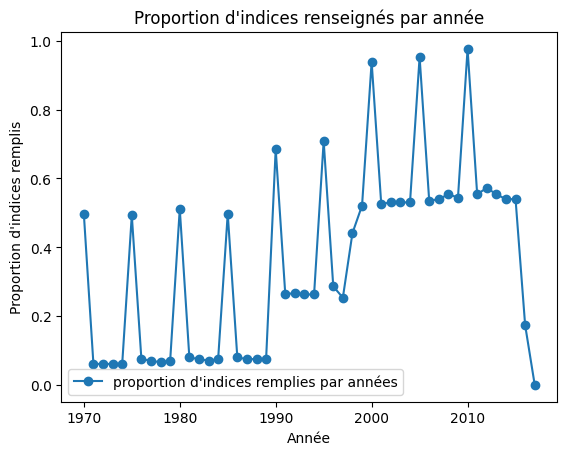

In [50]:
ProportionIdicateur.plot(x = 'index', y = "proportion d'indices remplies par années", kind = "line", marker ="o")
plt.title("Proportion d'indices renseignés par année")
plt.xlabel("Année")
plt.ylabel("Proportion d'indices remplis")

Ce graphique nous montre que les années possédant le plus données se situe après 1990. On pourra donc dans la suite, limiter le année de 1990 a 2017.

De même on détermine la proportion d'années remplies par indicateurs.

In [51]:
ProportionAnnees = Data.groupby(["Indicator Code"])[Passe].count().ne(0).mean(axis = 1).reset_index(name = "proportion d'années remplies par indicateur")
ProportionAnnees.head()

,Indicator Code,proportion d'années remplies par indicateur
0,BAR.NOED.1519.ZS,0.1875
1,BAR.NOED.15UP.ZS,0.1875
2,BAR.NOED.2024.ZS,0.1875
3,BAR.NOED.2529.ZS,0.1875
4,BAR.NOED.25UP.ZS,0.1875


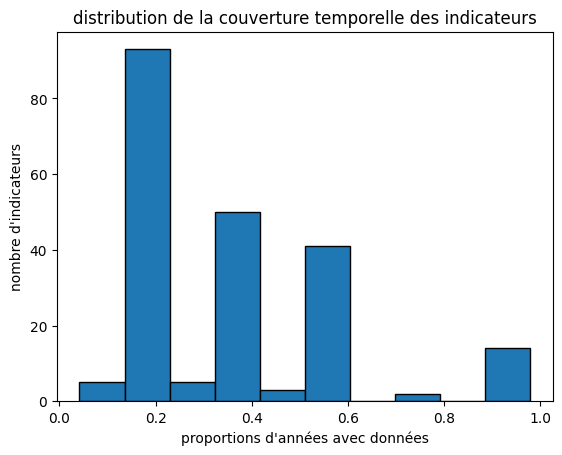

In [52]:
ProportionAnnees["proportion d'années remplies par indicateur"].plot(kind="hist", bins=10, edgecolor = "black", title = "distribution de la couverture temporelle des indicateurs")
plt.xlabel("proportions d'années avec données")
plt.ylabel("nombre d'indicateurs")
plt.show()

- Plus de 80 indicateurs qui ont aux alentour de 20% des années remplies   
- Plus de 40 indicateurs qui ont aux alentour de 40% des années remplies   
- Environ 40 indicateurs qui ont aux alentour de 60% des années remplies  
- Moins de 20 indicateurs qui ont aux alentours de 90% d'années renseignées.

Nombre de pays ayant une valeur pour un estimateur donné à une année donnée

In [53]:
Data_nombre_pays_transition = Data.copy() # copie de Data
annees = np.arange(1990, 2018).astype(str).tolist()
Data_nombre_pays_transition[annees] = Data_nombre_pays_transition[annees].notna() # on remplace chaque cases pour les années par un booléen (True si il y a une valeur, False si NaN)
Data_nombre_pays_transition["Total"] = Data_nombre_pays_transition[annees].any(axis =1) # On créé un colonne Total qui est True si il existe une valeur dans la ligne, False si il n'y a que des NaN (a ce stade chaque ligne represente un pays et un indicateur), si il existe au moins une valeur peu importe l'année, on a True et le pays sera bien comptabilisé une seule fois dans le décompte final.
Data_nombre_pays = Data_nombre_pays_transition.groupby(["Indicator Name", "Indicator Code", "Topic"])[annees+["Total"]].sum().sort_values(by = "Total", ascending = False).reset_index() # On regroupe par indicateur, on somme les cases d'une meme année d'un meme indicateur, ce qui donne le nombre de pays ayant une valeur pourcet indicateur.#Et on somme egalement sur la colonne Total par indicateur. ce qui donne le nombre de pays ayant au moins une valeur pour l'indicateur.
Data_nombre_pays.head()

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,...,2009,2010,2011,2012,2013,2014,2015,2016,2017,Total
0,"Population, total",SP.POP.TOTL,Health: Population: Structure,213,213,212,212,212,213,213,...,215,215,215,214,214,210,210,210,0,215
1,Internet users (per 100 people),IT.NET.USER.P2,Infrastructure: Communications,206,39,50,65,91,138,171,...,202,202,204,202,201,201,201,201,0,208
2,"Enrolment in secondary education, both sexes (number)",SE.SEC.ENRL,Secondary,131,134,131,129,131,116,107,...,152,150,155,149,140,140,122,8,0,207
3,"Enrolment in upper secondary education, both sexes (number)",UIS.E.3,Secondary,0,0,0,0,0,0,0,...,152,149,154,152,140,118,7,0,0,200
4,"Population of the official age for upper secondary education, both sexes (number)",SP.SEC.UTOT.IN,Population,188,188,188,188,188,188,188,...,195,194,195,195,195,196,194,157,0,199


Regardons ce tableau pour chaque Topic.

In [54]:
Data_nombre_pays["Topic"].unique()

<StringArray>
[                                        'Health: Population: Structure',
                                        'Infrastructure: Communications',
                                                             'Secondary',
                                                            'Population',
 'Economic Policy & Debt: National accounts: Atlas GNI & GNI per capita',
                                                              'Tertiary',
                       'Economic Policy & Debt: Purchasing power parity',
                                                            'Attainment',
                                                     'Learning Outcomes']
Length: 9, dtype: str

In [55]:
Data_nombre_pays.loc[Data_nombre_pays["Topic"] == "Tertiary"].head(5)

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,...,2009,2010,2011,2012,2013,2014,2015,2016,2017,Total
8,"Enrolment in tertiary education, all programmes, both sexes (number)",SE.TER.ENRL,Tertiary,123,123,117,111,103,110,105,...,136,140,142,141,131,124,109,7,0,198
9,"Total outbound internationally mobile tertiary students studying abroad, all countries, both sexes (number)",UIS.OE.56.40510,Tertiary,0,0,0,0,0,0,0,...,197,197,197,197,197,0,0,0,0,197
55,"Enrolment in tertiary education per 100,000 inhabitants, both sexes",UIS.TE_100000.56,Tertiary,121,119,113,108,101,109,103,...,135,136,138,132,123,93,4,0,0,190
56,"Gross enrolment ratio, tertiary, both sexes (%)",SE.TER.ENRR,Tertiary,121,120,113,108,101,109,103,...,132,133,138,136,125,119,99,7,0,190
61,"Graduates from tertiary education, both sexes (number)",SE.TER.GRAD,Tertiary,70,73,57,79,70,70,71,...,93,94,94,107,101,105,85,7,0,181


On prend les indicateurs pertinents parmis les 5 indicateurs les mieux remplis du Topic Tertiary: 
- Enrolment in tertiary education, all programmes, both sexes (number): SE.TER.ENRL
- Gross enrolment ratio, tertiary, both sexes (%) : SE.TER.ENRR 

In [56]:
Data_nombre_pays.loc[Data_nombre_pays["Topic"] == "Secondary"].head(5)

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,...,2009,2010,2011,2012,2013,2014,2015,2016,2017,Total
2,"Enrolment in secondary education, both sexes (number)",SE.SEC.ENRL,Secondary,131,134,131,129,131,116,107,...,152,150,155,149,140,140,122,8,0,207
3,"Enrolment in upper secondary education, both sexes (number)",UIS.E.3,Secondary,0,0,0,0,0,0,0,...,152,149,154,152,140,118,7,0,0,200
10,"Enrolment in secondary education, public institutions, both sexes (number)",UIS.E.23.PU,Secondary,0,0,0,0,0,0,0,...,127,138,141,135,131,110,5,0,0,197
11,"Enrolment in upper secondary education, public institutions, both sexes (number)",UIS.E.3.PU,Secondary,0,0,0,0,0,0,0,...,129,140,141,137,133,113,6,0,0,197
12,"Gross enrolment ratio, upper secondary, both sexes (%)",SE.SEC.ENRR.UP,Secondary,2,7,5,19,37,56,72,...,144,144,149,145,136,134,114,8,0,195


On prend les indicateurs pertinents parmis les 5 indicateurs les mieux remplis du Topic Tertiary:  
- Enrolment in upper secondary education, both sexes (number) 	UIS.E.3  
- Gross enrolment ratio, upper secondary, both sexes (%) 	SE.SEC.ENRR.UP

In [57]:
Data_nombre_pays.loc[Data_nombre_pays["Topic"] == "Health: Population: Structure"].head(5)

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,...,2009,2010,2011,2012,2013,2014,2015,2016,2017,Total
0,"Population, total",SP.POP.TOTL,Health: Population: Structure,213,213,212,212,212,213,213,...,215,215,215,214,214,210,210,210,0,215


Il n'y a qu'un seul indicateur:  
- Population, total 	SP.POP.TOTL

In [58]:
Data_nombre_pays.loc[Data_nombre_pays["Topic"] == "Infrastructure: Communications"].head(5)

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,...,2009,2010,2011,2012,2013,2014,2015,2016,2017,Total
1,Internet users (per 100 people),IT.NET.USER.P2,Infrastructure: Communications,206,39,50,65,91,138,171,...,202,202,204,202,201,201,201,201,0,208
14,Personal computers (per 100 people),IT.CMP.PCMP.P2,Infrastructure: Communications,61,65,70,78,91,109,116,...,3,0,0,0,0,0,0,0,0,193


L' indicateur Personal computers (per 100 people) 	IT.CMP.PCMP.P2, ne possède pas de données pour les années récentes, on   
préfèrera donc prendre l'indicateur:
- Internet users (per 100 people) 	IT.NET.USER.P2
- Personal computers (per 100 people) IT.CMP.PCMP.P2

In [59]:
Data_nombre_pays.loc[Data_nombre_pays["Topic"] == "Population"].head(5)

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,...,2009,2010,2011,2012,2013,2014,2015,2016,2017,Total
4,"Population of the official age for upper secondary education, both sexes (number)",SP.SEC.UTOT.IN,Population,188,188,188,188,188,188,188,...,195,194,195,195,195,196,194,157,0,199
6,"Population of the official age for secondary education, both sexes (number)",SP.SEC.TOTL.IN,Population,188,188,188,188,188,188,188,...,195,193,194,194,194,195,194,157,0,199
7,"Population of the official age for tertiary education, both sexes (number)",SP.TER.TOTL.IN,Population,188,188,188,188,188,188,188,...,194,191,174,168,162,194,128,7,0,199
16,"Population, ages 11-17, total",SP.POP.1117.TO.UN,Population,181,181,181,181,181,181,181,...,181,181,181,181,181,181,181,0,0,192
17,"Population, ages 11-16, total",SP.POP.1116.TO.UN,Population,181,181,181,181,181,181,181,...,181,181,181,181,181,181,181,0,0,192


On prend les indicateurs pertinents parmis les 5 indicateurs les mieux remplis du Topic Population:  
- Population of the official age for tertiary education, both sexes (number) 	SP.TER.TOTL.IN
- Population of the official age for upper secondary education, both sexes (number) 	SP.SEC.UTOT.IN

In [60]:
Data_nombre_pays.loc[Data_nombre_pays["Topic"] == "Economic Policy & Debt: National accounts: Atlas GNI & GNI per capita"].head(4)

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,...,2009,2010,2011,2012,2013,2014,2015,2016,2017,Total
5,"GNI per capita, Atlas method (current US$)",NY.GNP.PCAP.CD,Economic Policy & Debt: National accounts: Atlas GNI & GNI per capita,146,145,159,165,166,172,173,...,190,190,190,189,189,184,183,178,0,199


Il n'y a qu'un seul indicateur:  
- GNI per capita, Atlas method (current US$) 	NY.GNP.PCAP.CD

Cet indicateur ne prend pas en compte le pouvoir d'achat des habitants, il est donc peu pertinent pour notre étude. On ne le concerve pas.

In [61]:
Data_nombre_pays.loc[Data_nombre_pays["Topic"] == "Economic Policy & Debt: Purchasing power parity"].head(5)

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,...,2009,2010,2011,2012,2013,2014,2015,2016,2017,Total
15,"GDP per capita, PPP (constant 2011 international $)",NY.GDP.PCAP.PP.KD,Economic Policy & Debt: Purchasing power parity,165,167,169,170,171,179,180,...,190,190,192,188,188,185,184,181,0,192
24,"GDP, PPP (current international $)",NY.GDP.MKTP.PP.CD,Economic Policy & Debt: Purchasing power parity,165,167,170,171,172,179,180,...,190,190,192,188,188,185,184,181,0,192
25,"GDP, PPP (constant 2011 international $)",NY.GDP.MKTP.PP.KD,Economic Policy & Debt: Purchasing power parity,165,167,170,171,172,179,180,...,190,190,192,188,188,185,184,181,0,192
26,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,Economic Policy & Debt: Purchasing power parity,165,167,169,170,171,179,180,...,190,190,192,188,188,185,184,181,0,192
58,"GNI, PPP (current international $)",NY.GNP.MKTP.PP.CD,Economic Policy & Debt: Purchasing power parity,151,154,158,163,164,173,173,...,188,188,188,186,186,183,181,177,0,189


On s'interesse au pouvoir d'achat par habitant, les indicateurs les plus pertinent seront donc:  
- GDP per capita, PPP (current international \$) NY.GDP.PCAP.PP.CD
- GDP per capita, PPP (constant 2011 international $) 	NY.GDP.PCAP.PP.KD

In [62]:
Data_nombre_pays.loc[Data_nombre_pays["Topic"] == "Attainment"].head(5)

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,...,2009,2010,2011,2012,2013,2014,2015,2016,2017,Total
81,UIS: Percentage of population age 25+ with at least completed upper secondary education (ISCED 3 or higher). Total,UIS.EA.3T6.AG25T99,Attainment,9,9,3,3,2,5,3,...,62,74,70,62,55,65,56,2,0,152
83,UIS: Percentage of population age 25+ with at least a completed short-cycle tertiary degree (ISCED 5 or higher). Total,UIS.EA.5T8.AG25T99,Attainment,0,0,1,0,0,1,3,...,61,72,67,59,51,59,51,2,0,151
93,UIS: Percentage of population age 25+ with completed upper secondary education. Total,UIS.EA.3.AG25T99,Attainment,0,0,0,0,0,2,2,...,59,72,69,61,51,53,1,0,0,145
94,"Barro-Lee: Population in thousands, age 40-44, total",BAR.POP.4044,Attainment,144,0,0,0,0,144,0,...,0,144,0,0,0,0,0,0,0,144
95,"Barro-Lee: Population in thousands, age 35-39, total",BAR.POP.3539,Attainment,144,0,0,0,0,144,0,...,0,144,0,0,0,0,0,0,0,144


On concervera l'indicateur nous donnant le taux de bachelier:  
- UIS: Percentage of population age 25+ with at least completed upper secondary education (ISCED 3 or higher). Total 	UIS.EA.3T6.AG25T99


In [63]:
Data_nombre_pays.loc[Data_nombre_pays["Topic"] == "Learning Outcomes"].head(5)

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,...,2009,2010,2011,2012,2013,2014,2015,2016,2017,Total
209,PIAAC: Young adults by proficiency level in problem solving in technology-rich environments (%). No computer experience or failed the ICT core test,LO.PIAAC.TEC.YOU.FAILNO,Learning Outcomes,0,0,0,0,0,0,0,...,0,0,0,22,0,0,8,0,0,30
210,PIAAC: Adults by proficiency level in problem solving in technology-rich environments (%). Opted out of computer-based assessment,LO.PIAAC.TEC.OPT,Learning Outcomes,0,0,0,0,0,0,0,...,0,0,0,22,0,0,8,0,0,30
211,PIAAC: Adults by proficiency level in problem solving in technology-rich environments (%). No computer experience,LO.PIAAC.TEC.NO,Learning Outcomes,0,0,0,0,0,0,0,...,0,0,0,22,0,0,8,0,0,30
212,PIAAC: Young adults by proficiency level in problem solving in technology-rich environments (%). Opted out of computer-based assessment,LO.PIAAC.TEC.YOU.OPT,Learning Outcomes,0,0,0,0,0,0,0,...,0,0,0,22,0,0,7,0,0,29


Tout ces indicateurs possèdent peu de valeurs, nous n'en garderons aucun.

**On récapitule la liste des indicateurs que nous venons de selectionner:**  
- Population, total: SP.POP.TOTL
- Internet users (per 100 people): IT.NET.USER.P2
- Personal computers (per 100 people) IT.CMP.PCMP.P2
- Population of the official age for tertiary education, both sexes (number) 	: SP.TER.TOTL.IN
- Enrolment in tertiary education, all programmes, both sexes (number) 	SE.TER.ENRL
- Gross enrolment ratio, tertiary, both sexes (%) : SE.TER.ENRR 	
- Population of the official age for upper secondary education, both sexes (number) : SP.SEC.UTOT.IN
- Enrolment in upper secondary education, both sexes (number) : UIS.E.3
- Gross enrolment ratio, upper secondary, both sexes (%) : SE.SEC.ENRR.UP
- UIS: Percentage of population age 25+ with at least completed upper secondary education (ISCED 3 or higher). Total : UIS.EA.3T6.AG25T99
- GDP per capita, PPP (current international \$) : NY.GDP.PCAP.PP.CD
- GDP per capita, PPP (constant 2011 international \$) : NY.GDP.PCAP.PP.KD

In [64]:
# On filtre EdStatsData selon les indicateurs précités.
Indicateurs = ["SP.POP.TOTL", "IT.NET.USER.P2","IT.CMP.PCMP.P2", "SP.TER.TOTL.IN", "SE.TER.ENRL", "SE.TER.ENRR", "SP.SEC.UTOT.IN", "UIS.E.3", "SE.SEC.ENRR.UP", "UIS.EA.3T6.AG25T99", "NY.GDP.PCAP.PP.CD", "NY.GDP.PCAP.PP.KD"]
Data = Data.loc[Data["Indicator Code"].isin(Indicateurs)]
Data.head()

,Country Name,Country Code,Region,Income Group,Topic,Indicator Name,Indicator Code,1970,1971,1972,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
97,Afghanistan,AFG,South Asia,Low income,Tertiary,"Enrolment in tertiary education, all programmes, both sexes (number)",SE.TER.ENRL,7732.00000,9409.00000,9817.00000,...,NaN,95185.000000,NaN,97504.000000,NaN,NaN,262874.000000,NaN,NaN,NaN
102,Afghanistan,AFG,South Asia,Low income,Secondary,"Enrolment in upper secondary education, both sexes (number)",UIS.E.3,NaN,NaN,NaN,...,361193.000000,443002.000000,567344.000000,743405.000000,881415.000000,969267.000000,968769.000000,NaN,NaN,NaN
105,Afghanistan,AFG,South Asia,Low income,Economic Policy & Debt: Purchasing power parity,"GDP per capita, PPP (constant 2011 international $)",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,...,1298.143159,1531.173993,1614.255001,1660.739856,1839.273579,1814.155825,1780.382366,1747.978457,1739.583177,NaN
106,Afghanistan,AFG,South Asia,Low income,Economic Policy & Debt: Purchasing power parity,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,NaN,NaN,NaN,...,1247.066144,1482.098837,1581.600836,1660.739856,1873.153946,1877.411953,1875.447407,1864.973641,1879.695509,NaN
118,Afghanistan,AFG,South Asia,Low income,Tertiary,"Gross enrolment ratio, tertiary, both sexes (%)",SE.TER.ENRR,0.76817,0.92394,0.95241,...,NaN,3.903390,NaN,3.755980,NaN,NaN,8.662800,NaN,NaN,NaN


## **Nettoyage**

Déterminons pour chaque pays le nombre d'indicateurs ayant au moins une valeur par pays.

In [65]:
pd.set_option("display.max_rows", None)
DataNotnaIndicateurs = Data.copy()
DataNotnaIndicateurs["nombre indicateurs"] = DataNotnaIndicateurs[Passe].notna().any(axis = 1)
DataNombreIndicateursParPays = DataNotnaIndicateurs.groupby("Country Name")["nombre indicateurs"].sum().reset_index().sort_values(by = "nombre indicateurs", ascending = True)
DataNombreIndicateursParPays

,Country Name,nombre indicateurs
38,Channel Islands,1
92,Isle of Man,1
181,St. Martin (French part),1
144,Northern Mariana Islands,2
103,Kosovo,3
170,Sint Maarten (Dutch part),3
63,Faroe Islands,3
3,American Samoa,3
129,Monaco,3
211,Virgin Islands (U.S.),4


Les pays avec moins de 8 indicateurs renseignés sont trop peu exploitables, on ne les conserve pas dans l'étude.

In [66]:
PaysPeuExploitables = DataNombreIndicateursParPays.loc[DataNombreIndicateursParPays["nombre indicateurs"] <= 8]["Country Name"].tolist()
PaysPeuExploitables

['Channel Islands',
 'Isle of Man',
 'St. Martin (French part)',
 'Northern Mariana Islands',
 'Kosovo',
 'Sint Maarten (Dutch part)',
 'Faroe Islands',
 'American Samoa',
 'Monaco',
 'Virgin Islands (U.S.)',
 'Nauru',
 'New Caledonia',
 'Turks and Caicos Islands',
 'Greenland',
 'Guam',
 'French Polynesia',
 'Gibraltar',
 'Andorra',
 'Curacao',
 'South Sudan',
 'Korea, Dem. People’s Rep.']

In [67]:
Data = Data.loc[~Data["Country Name"].isin(PaysPeuExploitables)]
Data.shape

(2340, 55)

Pour suivre une formation en e-learning, internet est une necéssité, donc on ne concerve pas les pays sans données sur les utilisateurs d'internet.

In [68]:
Data.loc[(Data["Indicator Code"] == "IT.NET.USER.P2") & (Data.loc[:, annees].isna().all(axis=1))]["Country Name"].tolist()

[]

In [69]:
Data = Data.loc[Data["Country Name"] != "South Sudan"]
Data.shape

(2340, 55)

De même on ne concerve pas les pays sans données économiques.

In [70]:
PibDollarInternationauxNan = set(Data.loc[(Data["Indicator Code"] == "NY.GDP.PCAP.PP.CD") & (Data.loc[:, Passe].isna().all(axis=1))]["Country Name"])
PibDollarConstantNan = set(Data.loc[(Data["Indicator Code"] == "NY.GDP.PCAP.PP.KD") & (Data.loc[:, Passe].isna().all(axis=1))]["Country Name"])
PaysIndicateursEconomiquesNonRenseignés = list(set(PibDollarInternationauxNan) & set(PibDollarConstantNan))
PaysIndicateursEconomiquesNonRenseignés

['Syrian Arab Republic',
 'Cuba',
 'Liechtenstein',
 'West Bank and Gaza',
 'Somalia']

In [71]:
Data = Data.loc[~Data["Country Name"].isin(PaysIndicateursEconomiquesNonRenseignés)]
Data.shape

(2280, 55)

Cherchons l'année à partir de laquelle on obtient un maximum de données pour nos indicateurs.
On en concervera pas des années trop anciennes (système scolaire, populations, taux de d'élèves dans le secondaires, seraient trop différents des données actuelles).
On cherche des données relativement récentes.

In [72]:
yearstodrop = np.arange(1970, 1990).astype(str).tolist()
Data = Data.drop(yearstodrop, axis =1)
DataBfill = Data.bfill(axis = 1).groupby(["Indicator Name", "Indicator Code", "Topic"])[annees].count().reset_index().sort_values(by = "Topic", ascending = False)
DataBfill

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
0,"Enrolment in tertiary education, all programmes, both sexes (number)",SE.TER.ENRL,Tertiary,186,185,185,185,184,184,183,...,166,164,162,158,153,141,129,102,7,0
4,"Gross enrolment ratio, tertiary, both sexes (%)",SE.TER.ENRR,Tertiary,184,183,183,183,181,181,180,...,161,160,158,154,149,136,125,95,7,0
1,"Enrolment in upper secondary education, both sexes (number)",UIS.E.3,Secondary,187,187,187,187,187,187,187,...,177,173,171,166,162,146,111,6,0,0
5,"Gross enrolment ratio, upper secondary, both sexes (%)",SE.SEC.ENRR.UP,Secondary,186,186,185,185,185,185,185,...,173,169,168,165,162,150,139,110,8,0
8,"Population of the official age for tertiary education, both sexes (number)",SP.TER.TOTL.IN,Population,188,188,188,188,188,188,188,...,185,185,185,185,185,185,185,124,7,0
9,"Population of the official age for upper secondary education, both sexes (number)",SP.SEC.UTOT.IN,Population,188,188,188,188,188,188,188,...,187,187,187,187,187,187,187,185,152,0
6,Internet users (per 100 people),IT.NET.USER.P2,Infrastructure: Communications,190,190,190,190,190,190,190,...,189,189,189,189,188,188,188,188,188,0
7,Personal computers (per 100 people),IT.CMP.PCMP.P2,Infrastructure: Communications,183,183,183,183,183,183,183,...,26,3,0,0,0,0,0,0,0,0
10,"Population, total",SP.POP.TOTL,Health: Population: Structure,190,190,190,190,190,190,190,...,190,190,190,190,189,189,189,189,189,0
2,"GDP per capita, PPP (constant 2011 international $)",NY.GDP.PCAP.PP.KD,Economic Policy & Debt: Purchasing power parity,190,190,190,190,190,190,190,...,190,190,190,190,186,186,184,183,180,0


In [73]:
DataBfill.loc[DataBfill["Topic"]=="Attainment"]

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
11,UIS: Percentage of population age 25+ with at least completed upper secondary education (ISCED 3 or higher). Total,UIS.EA.3T6.AG25T99,Attainment,144,143,143,143,143,143,142,...,124,122,116,100,86,78,70,55,2,0


Pour les indicateurs:  
- GDP per capita, PPP (current international \$) 	NY.GDP.PCAP.PP.CD
- GDP per capita, PPP (constant 2011 international \$) 	NY.GDP.PCAP.PP.KD
- Population, total 	SP.POP.TOTL
- Internet users (per 100 people) 	IT.NET.USER.P2

l'année 2016 est très bien remplie, donc on ne concerve que l'année 2016 pour ces indicateurs.

Pour les indicateurs de population:  
- Population of the official age for tertiary education, both sexes (number) 	SP.TER.TOTL.IN
- Population of the official age for upper secondary education, both sexes (number) 	SP.SEC.UTOT.IN

Il faut remonter à 2014 pour que presque tous les pays soient remplis. Etant donné que les indicateurs de population évoluent relativement  
lentement on pourra donc remonter jusqu'à cette année pour obtenir une valeur pour ces indicateurs.

In [74]:
Data.loc[Data["Indicator Code"].isin(["SP.TER.TOTL.IN", "SP.SEC.UTOT.IN"]), Data.columns[7:-1]] = Data.loc[Data["Indicator Code"].isin(["SP.TER.TOTL.IN", "SP.SEC.UTOT.IN"]), Data.columns[7:-1]].ffill(axis = 1, limit = 3)

L'indicateur donnant le nombre de bacheliers UIS: Percentage of population age 25+ with at least completed upper secondary education (ISCED 3 or higher). Total 	UIS.EA.3T6.AG25T99) , est très mal remplis, donc on ne le concervera pas. On préférera les indicateurs :
- Population of the official age for tertiary education, both sexes (number) 	SP.TER.TOTL.IN
- Population of the official age for upper secondary education, both sexes (number) 	SP.SEC.UTOT.IN 	

In [75]:
Data = Data.loc[~Data["Indicator Code"].isin(["UIS.EA.3T6.AG25T99"])]
Data.shape

(2090, 35)

Les indicateurs décrivant la population cible:  
- Enrolment in tertiary education, all programmes, both sexes (number) 	SE.TER.ENRL
- Gross enrolment ratio, tertiary, both sexes (%) 	SE.TER.ENRR
- Enrolment in upper secondary education, both sexes (number) 	UIS.E.3
- Gross enrolment ratio, upper secondary, both sexes (%) 	SE.SEC.ENRR.UP

Ainsi que l'indicateur donnant le taux de personnes informatisées:
- Personal computers (per 100 people) 	IT.CMP.PCMP.P2

Sont assez mal remplis sur la dernière année. Nous allons donc nous attarder sur les années antèrieurs récentes, afin de verifier si elles peuvent constituer une bonne approche pour combler ce manque de données.

Ce tableau nous permet de voir, pour chaque pays, quelle est l'année la plus récente pour laquelle un maximum de nos indicateurs sont remplis.

In [76]:
DataBfillPays = Data.bfill(axis = 1).groupby("Country Name")[annees].count().reset_index()
DataBfillPays.sort_values(by = "1998")

,Country Name,1990,1991,1992,1993,1994,1995,1996,1997,1998,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
33,Cayman Islands,6,6,6,6,6,6,6,6,6,...,6,5,5,5,3,3,2,2,2,0
72,Haiti,7,7,7,7,7,7,7,7,7,...,6,6,6,6,6,6,6,6,6,0
151,Singapore,7,7,7,7,7,7,7,7,7,...,6,6,5,5,5,5,4,4,4,0
49,Dominica,11,11,11,11,9,9,9,9,9,...,8,8,8,8,8,8,8,7,6,0
89,Kiribati,9,9,9,9,9,9,9,9,9,...,8,6,6,6,6,6,6,6,6,0
176,Tuvalu,9,9,9,9,9,9,9,9,9,...,8,8,8,8,8,8,8,6,6,0
154,Solomon Islands,9,9,9,9,9,9,9,9,9,...,8,8,8,8,8,6,6,6,6,0
11,"Bahamas, The",11,11,11,11,11,11,9,9,9,...,8,8,8,6,6,6,6,6,6,0
160,St. Vincent and the Grenadines,11,9,9,9,9,9,9,9,9,...,8,8,8,8,8,8,8,7,6,0
188,Zambia,9,9,9,9,9,9,9,9,9,...,8,8,8,8,8,6,6,6,6,0


In [77]:
Paysinexploitables = DataBfillPays.loc[DataBfillPays["1998"] <= 9 ]["Country Name"].tolist()
Paysinexploitables

['Bahamas, The',
 'Cayman Islands',
 'Dominica',
 'Haiti',
 'Kiribati',
 'Singapore',
 'Solomon Islands',
 'St. Vincent and the Grenadines',
 'Tuvalu',
 'Zambia']

On peut supprimer ces pays car il s'agit d'îles, souvent très pauvres ou simplement très mal renseignées.

In [78]:
Data = Data.loc[~Data["Country Name"].isin(Paysinexploitables)]
Data.shape

(1980, 35)

Attardons nous sur les pays restants pour nos indicateurs précité, et verifions si ces derniers évoluent plus ou moins lentement aucours du temps.

In [79]:
DataBfill.loc[DataBfill["Indicator Code"].isin(["SE.TER.ENRL", "SE.TER.ENRR", "UIS.E.3", "SE.SEC.ENRR.UP", "IT.CMP.PCMP.P2" ])]

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
0,"Enrolment in tertiary education, all programmes, both sexes (number)",SE.TER.ENRL,Tertiary,186,185,185,185,184,184,183,...,166,164,162,158,153,141,129,102,7,0
4,"Gross enrolment ratio, tertiary, both sexes (%)",SE.TER.ENRR,Tertiary,184,183,183,183,181,181,180,...,161,160,158,154,149,136,125,95,7,0
1,"Enrolment in upper secondary education, both sexes (number)",UIS.E.3,Secondary,187,187,187,187,187,187,187,...,177,173,171,166,162,146,111,6,0,0
5,"Gross enrolment ratio, upper secondary, both sexes (%)",SE.SEC.ENRR.UP,Secondary,186,186,185,185,185,185,185,...,173,169,168,165,162,150,139,110,8,0
7,Personal computers (per 100 people),IT.CMP.PCMP.P2,Infrastructure: Communications,183,183,183,183,183,183,183,...,26,3,0,0,0,0,0,0,0,0


Pour les indicateurs concernant le nombre d'élèves:  
- SE.TER.ENRL (Enrolment in tertiary education, all programmes, both sexes (number))
- UIS.E.3 	(Enrolment in upper secondary education, both sexes (number))
  
On peut remonter jusqu'en 2013 pour compléter nos données manquantes, étant donné qu'un système scolaire ne peut généralement pas changer en 3 ans. On se contentera de cette approximation imparfaite et incomplète pour les indicateurs en valeur brute du nombre d'élèves, étant donné que dans la suite, pour des raisons pratiques on préférera utiliser les indicateurs en pourcentages.

In [80]:
Data.loc[Data["Indicator Code"].isin(["SE.TER.ENRL", "UIS.E.3"]), Data.columns[7:-1]] = Data.loc[Data["Indicator Code"].isin(["SE.TER.ENRL", "UIS.E.3"]), Data.columns[7:-1]].ffill(axis = 1, limit = 3)

Atardons nous plus en détail sur les indicateurs correspondat aux pourcentages d'élèves:  
- SE.TER.ENRR  (Gross enrolment ratio, tertiary, both sexes (%))
- SE.SEC.ENRR.UP (Gross enrolment ratio, upper secondary, both sexes (%))

### Taux d'enrôlements dans le tertiaire

In [81]:
DataBfill.loc[DataBfill["Indicator Code"] == "SE.TER.ENRR"]

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
4,"Gross enrolment ratio, tertiary, both sexes (%)",SE.TER.ENRR,Tertiary,184,183,183,183,181,181,180,...,161,160,158,154,149,136,125,95,7,0


Dans un premier temps peut remonter jusqu'en 2013 pour compléter nos données manquantes, étant donné qu'un système scolaire ne peut généralement pas changer en 3 ans.

Regardons les Region et Income Groupe des pays sans données à partir de 2013.

In [82]:
RegionGroupeAncien = Data.bfill(axis = 1).loc[(Data.bfill(axis = 1)["Indicator Code"] == "SE.TER.ENRR") & (Data.bfill(axis = 1)["2013"].isna())].groupby(["Region", "Income Group"])["Country Name"].count().reset_index().sort_values(by ="Country Name", ascending = False)
RegionGroupeAncien

,Region,Income Group,Country Name
14,Sub-Saharan Africa,Low income,9
1,East Asia & Pacific,Lower middle income,5
7,Latin America & Caribbean,Lower middle income,4
8,Latin America & Caribbean,Upper middle income,3
6,Latin America & Caribbean,High income: nonOECD,3
2,East Asia & Pacific,Upper middle income,3
16,Sub-Saharan Africa,Upper middle income,2
5,Europe & Central Asia,Upper middle income,2
3,Europe & Central Asia,High income: OECD,2
11,Middle East & North Africa,Upper middle income,2


Attardons nous sur les Region et Income Group ou il y a le plus de pays sans valeurs en 2013 (plus de 3 pays).

In [83]:
RegionIncome = list(RegionGroupeAncien.loc[RegionGroupeAncien["Country Name"] >= 3][["Region", "Income Group"]].itertuples(index = False, name = None))
DataPourcentageTertiaire = Data.bfill(axis=1).loc[(Data.bfill(axis=1)["Indicator Code"] == "SE.TER.ENRR") & (Data[["Region", "Income Group"]].apply(tuple, axis = 1).isin(RegionIncome))].iloc[:,0:7]
DataPourcentageTertiaire["2009"] = Data.bfill(axis=1)["2009"]
DataPourcentageTertiaire["2013"] = Data.bfill(axis=1)["2013"]
DataPourcentageTertiaire = DataPourcentageTertiaire.melt(id_vars = ["Country Name", "Country Code", "Region", "Income Group", "Topic", "Indicator Name", "Indicator Code"], value_vars = ["2009", "2013"], var_name = "annee", value_name = "valeur")
DataPourcentageTertiaire.head()

,Country Name,Country Code,Region,Income Group,Topic,Indicator Name,Indicator Code,annee,valeur
0,Antigua and Barbuda,ATG,Latin America & Caribbean,High income: nonOECD,Tertiary,"Gross enrolment ratio, tertiary, both sexes (%)",SE.TER.ENRR,2009,14.81005
1,Argentina,ARG,Latin America & Caribbean,Upper middle income,Tertiary,"Gross enrolment ratio, tertiary, both sexes (%)",SE.TER.ENRR,2009,70.533287
2,Aruba,ABW,Latin America & Caribbean,High income: nonOECD,Tertiary,"Gross enrolment ratio, tertiary, both sexes (%)",SE.TER.ENRR,2009,35.36232
3,Barbados,BRB,Latin America & Caribbean,High income: nonOECD,Tertiary,"Gross enrolment ratio, tertiary, both sexes (%)",SE.TER.ENRR,2009,75.716248
4,Belize,BLZ,Latin America & Caribbean,Upper middle income,Tertiary,"Gross enrolment ratio, tertiary, both sexes (%)",SE.TER.ENRR,2009,22.41008


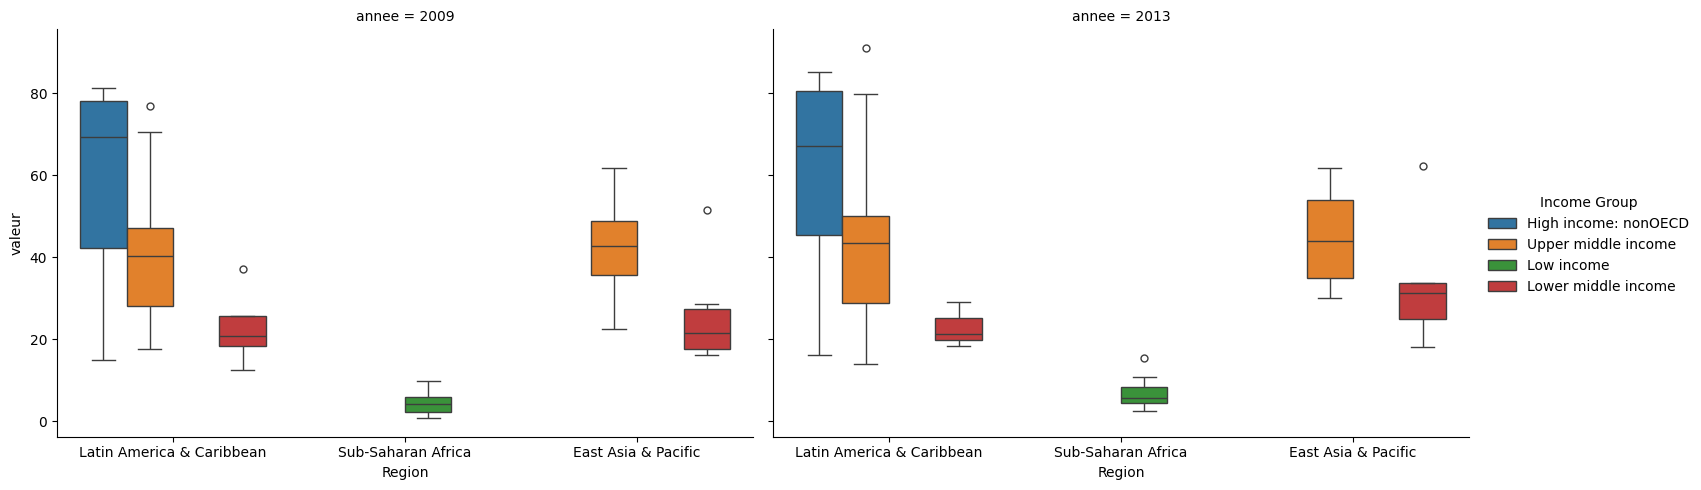

In [84]:
sns.catplot(data = DataPourcentageTertiaire, x = "Region", y = "valeur", hue = "Income Group", col = "annee", kind = "box", height = 5, aspect = 1.5)

Les boxplot des region income group, sont assez similaire en 2009 et 2013 pour l'indicateur SE.TER.ENRR, ce qui montre une stabilité globale et rend acceptable bien qu'imparfait le fait de remonter jusqu'en 2009 pour combler un maximum de valeurs manquantes pour cet indicateur.

Comme on l'a dit précédemment un système scolaire ne change pas en 3 ans donc on peu récupérer les valeurs jusqu'en 2013.

In [85]:
Data.loc[Data["Indicator Code"]== "SE.TER.ENRR", Data.columns[-5:-1]] = Data.loc[Data["Indicator Code"]== "SE.TER.ENRR", Data.columns[-5:-1]].ffill(axis = 1)

Et d'après le graphique que l'on vient de voir, on peut remonter jusqu'en 2009 au plus tard pour les pays des region/IncomeGroup:  
- Sub-Saharan Africa/Low income
- East Asia & Pacific/Lower middle income
- Latin America & Caribbean/Lower middle income
- Latin America & Caribbean/Upper middle income
- Latin America & Caribbean/High income: nonOECD
- East Asia & Pacific/Upper middle income 

In [86]:
Data.loc[(Data["Indicator Code"]== "SE.TER.ENRR") & (Data[["Region", "Income Group"]].apply(tuple, axis = 1).isin(RegionIncome)), Data.columns[7:-1]] = Data.loc[(Data["Indicator Code"]== "SE.TER.ENRR") & (Data[["Region", "Income Group"]].apply(tuple, axis = 1).isin(RegionIncome)), Data.columns[7:-1]].ffill(axis = 1, limit = 7)

In [87]:
RegionGroupeAncienRest = Data.loc[(Data["Indicator Code"] == "SE.TER.ENRR") & (Data["2016"].isna())].groupby(["Region", "Income Group"])["Country Name"].count().reset_index().sort_values(by ="Country Name", ascending = False)
RegionGroupeAncienRest

,Region,Income Group,Country Name
1,East Asia & Pacific,Lower middle income,4
16,Sub-Saharan Africa,Upper middle income,2
2,East Asia & Pacific,Upper middle income,2
3,Europe & Central Asia,High income: OECD,2
5,Europe & Central Asia,Upper middle income,2
7,Latin America & Caribbean,Lower middle income,2
11,Middle East & North Africa,Upper middle income,2
10,Middle East & North Africa,Lower middle income,2
9,Middle East & North Africa,High income: nonOECD,2
14,Sub-Saharan Africa,Low income,2


On remplace les valeurs maquantes des derniers pays par la mediane des pays de la region et de l'income Group.

In [88]:
RegionIncomeRest = list(RegionGroupeAncienRest[["Region", "Income Group"]].itertuples(index = False, name = None))
for region, income in RegionIncomeRest:
    mask = ((Data["Indicator Code"] == "SE.TER.ENRR") & (Data["Region"] == region) & (Data["Income Group"] == income))
    subset = Data.loc[mask, "2016"]
    if subset.notna().any():
        Data.loc[mask & Data["2016"].isna(), "2016"] = subset.median()

### Taux d'enrôlements dans le secondaire supérieur

In [89]:
DataBfill.loc[DataBfill["Indicator Code"] == "SE.SEC.ENRR.UP"]

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
5,"Gross enrolment ratio, upper secondary, both sexes (%)",SE.SEC.ENRR.UP,Secondary,186,186,185,185,185,185,185,...,173,169,168,165,162,150,139,110,8,0


In [90]:
RegionGroupeAncien = Data.bfill(axis = 1).loc[(Data.bfill(axis = 1)["Indicator Code"] == "SE.SEC.ENRR.UP") & (Data.bfill(axis = 1)["2013"].isna())].groupby(["Region", "Income Group"])["Country Name"].count().reset_index().sort_values(by ="Country Name", ascending = False)
RegionGroupeAncien

,Region,Income Group,Country Name
12,Sub-Saharan Africa,Low income,6
14,Sub-Saharan Africa,Upper middle income,5
1,East Asia & Pacific,Lower middle income,3
6,Latin America & Caribbean,Lower middle income,3
9,Middle East & North Africa,Upper middle income,3
5,Latin America & Caribbean,High income: nonOECD,2
4,Europe & Central Asia,Upper middle income,2
7,Middle East & North Africa,High income: nonOECD,2
3,Europe & Central Asia,High income: nonOECD,1
0,East Asia & Pacific,Low income,1


In [91]:
RegionIncome = list(RegionGroupeAncien.loc[RegionGroupeAncien["Country Name"] >= 3][["Region", "Income Group"]].itertuples(index = False, name = None))
DataPourcentageSecondaire = Data.bfill(axis=1).loc[(Data.bfill(axis=1)["Indicator Code"] == "SE.SEC.ENRR.UP") & (Data[["Region", "Income Group"]].apply(tuple, axis = 1).isin(RegionIncome))].iloc[:,0:7]
DataPourcentageSecondaire["2009"] = Data.bfill(axis=1)["2009"]
DataPourcentageSecondaire["2013"] = Data.bfill(axis=1)["2013"]
DataPourcentageSecondaire = DataPourcentageSecondaire.melt(id_vars = ["Country Name", "Country Code", "Region", "Income Group", "Topic", "Indicator Name", "Indicator Code"], value_vars = ["2009", "2013"], var_name = "annee", value_name = "valeur")
DataPourcentageSecondaire.head()

,Country Name,Country Code,Region,Income Group,Topic,Indicator Name,Indicator Code,annee,valeur
0,Algeria,DZA,Middle East & North Africa,Upper middle income,Secondary,"Gross enrolment ratio, upper secondary, both sexes (%)",SE.SEC.ENRR.UP,2009,49.46637
1,Angola,AGO,Sub-Saharan Africa,Upper middle income,Secondary,"Gross enrolment ratio, upper secondary, both sexes (%)",SE.SEC.ENRR.UP,2009,19.25832
2,Benin,BEN,Sub-Saharan Africa,Low income,Secondary,"Gross enrolment ratio, upper secondary, both sexes (%)",SE.SEC.ENRR.UP,2009,31.033899
3,Bolivia,BOL,Latin America & Caribbean,Lower middle income,Secondary,"Gross enrolment ratio, upper secondary, both sexes (%)",SE.SEC.ENRR.UP,2009,77.156349
4,Botswana,BWA,Sub-Saharan Africa,Upper middle income,Secondary,"Gross enrolment ratio, upper secondary, both sexes (%)",SE.SEC.ENRR.UP,2009,NaN


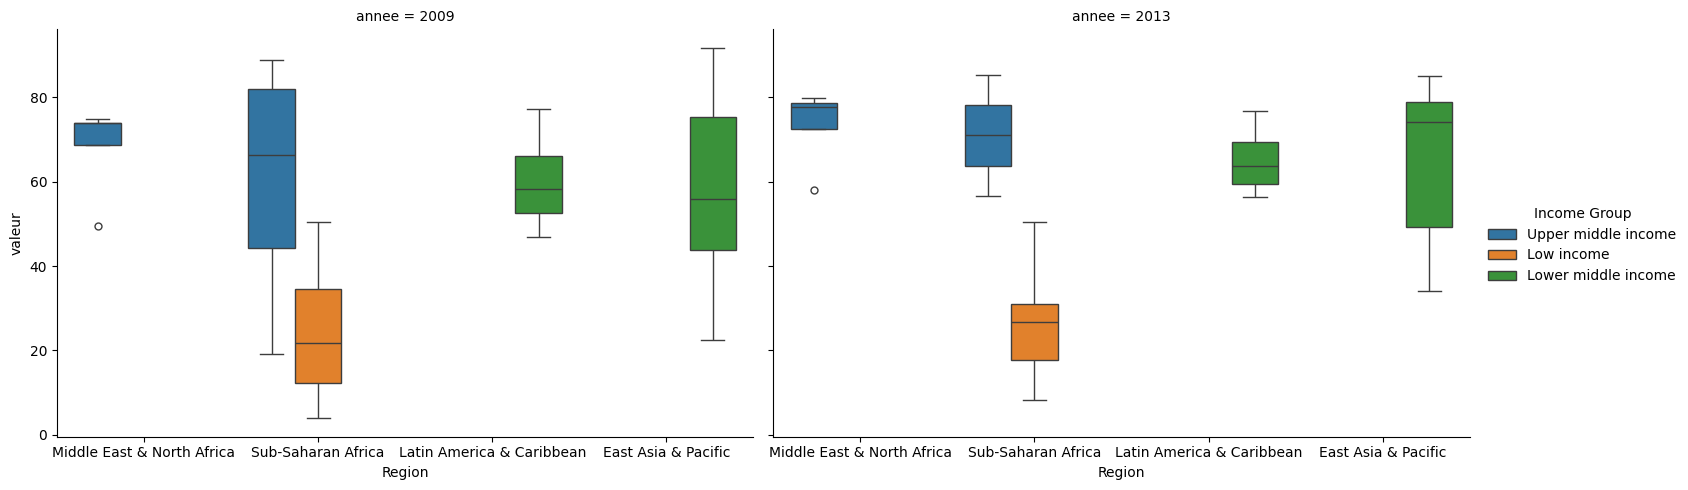

In [92]:
sns.catplot(data = DataPourcentageSecondaire, x = "Region", y = "valeur", hue = "Income Group", col = "annee", kind = "box", height = 5, aspect = 1.5)

Les boxplot des region income group, sont assez similaire en 2009 et 2013 pour l'indicateur SE.SEC.ENRR.UP, ce qui montre une stabilité globale et rend acceptable bien qu'imparfait le fait de remonter jusqu'en 2009 pour combler un maximum de valeurs manquantes pour cet indicateur.

Comme on l'a dit précédemment un système scolaire ne change pas en 3 ans donc on peu récupérer les valeurs jusqu'en 2013.

In [93]:
Data.loc[Data["Indicator Code"]== "SE.SEC.ENRR.UP", Data.columns[-5:-1]] = Data.loc[Data["Indicator Code"]== "SE.SEC.ENRR.UP", Data.columns[-5:-1]].ffill(axis = 1)

Et d'après le graphique que l'on vient de voir, on peut remonter jusqu'en 2009 au plus tard pour les pays des region/IncomeGroup:  
- Sub-Saharan Africa/Low income
- Sub-Saharan Africa/Upper middle income
- East Asia & Pacific/Lower middle income
- Latin America & Caribbean/Lower middle income
- Middle East & North Africa/Upper middle income

In [94]:
Data.loc[(Data["Indicator Code"]== "SE.SEC.ENRR.UP") & (Data[["Region", "Income Group"]].apply(tuple, axis = 1).isin(RegionIncome)), Data.columns[7:-1]] = Data.loc[(Data["Indicator Code"]== "SE.SEC.ENRR.UP") & (Data[["Region", "Income Group"]].apply(tuple, axis = 1).isin(RegionIncome)), Data.columns[7:-1]].ffill(axis = 1, limit = 7)

In [95]:
RegionGroupeAncienRest = Data.loc[(Data["Indicator Code"] == "SE.SEC.ENRR.UP") & (Data["2016"].isna())].groupby(["Region", "Income Group"])["Country Name"].count().reset_index().sort_values(by ="Country Name", ascending = False)
RegionGroupeAncienRest

,Region,Income Group,Country Name
13,Sub-Saharan Africa,Upper middle income,3
1,East Asia & Pacific,Lower middle income,2
4,Europe & Central Asia,Upper middle income,2
11,Sub-Saharan Africa,Low income,2
6,Middle East & North Africa,High income: nonOECD,2
5,Latin America & Caribbean,High income: nonOECD,2
8,Middle East & North Africa,Upper middle income,2
2,East Asia & Pacific,Upper middle income,1
0,East Asia & Pacific,Low income,1
3,Europe & Central Asia,High income: nonOECD,1


On remplace les valeurs maquantes des derniers pays par la mediane des pays de la region et de l'income Group.

In [96]:
RegionIncomeRest = list(RegionGroupeAncienRest[["Region", "Income Group"]].itertuples(index = False, name = None))
for region, income in RegionIncomeRest:
    mask = ((Data["Indicator Code"] == "SE.SEC.ENRR.UP") & (Data["Region"] == region) & (Data["Income Group"] == income))
    subset = Data.loc[mask, "2016"]
    if subset.notna().any():
        Data.loc[mask & Data["2016"].isna(), "2016"] = subset.median()

### Ordinateurs

In [97]:
pd.set_option('display.max_columns', None)
DataBfill.loc[DataBfill["Indicator Code"] == "IT.CMP.PCMP.P2"]

,Indicator Name,Indicator Code,Topic,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
7,Personal computers (per 100 people),IT.CMP.PCMP.P2,Infrastructure: Communications,183,183,183,183,183,183,183,183,183,183,183,183,182,180,176,167,101,49,26,3,0,0,0,0,0,0,0,0


Cet indicateur n'est plus remplis a partir de 2010, très incomplet à partir de 2006, et inexploitable à partir de 2007.  
On cherche a comparer les pays et non les années, on va donc prendre comme année de référence pour comparer les pays, une année suffisament bien remplie, et la moins ancienne possible. L'année 2005 est une bonne candidate.

In [98]:
OrdinateurManquant = Data.bfill(axis = 1).loc[(Data.bfill(axis = 1)["Indicator Code"] == "IT.CMP.PCMP.P2") & (Data.bfill(axis = 1).loc[:,"2005"].isna())]["Country Name"].tolist()
OrdinateurManquant

['Australia',
 'Bermuda',
 'Croatia',
 'Dominican Republic',
 'Grenada',
 'Guyana',
 'Iraq',
 'Israel',
 'Japan',
 'Kazakhstan',
 'Liberia',
 'Malta',
 'Marshall Islands',
 'Montenegro',
 'Pakistan',
 'Palau',
 'Sierra Leone',
 'St. Kitts and Nevis',
 'St. Lucia',
 'Timor-Leste']

In [99]:
mask = Data["Indicator Code"] == "IT.CMP.PCMP.P2"
Data.loc[mask, "2016"] = Data.loc[mask, "2005"]

In [100]:
DataBfillPays2 = Data.bfill(axis = 1).groupby("Country Name")[annees].count().reset_index().drop(np.arange(1990, 2000).astype(str).tolist(), axis =1).sort_values(by = "2016")
DataBfillPays2

,Country Name,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
51,Equatorial Guinea,11,10,10,10,9,9,8,8,8,7,7,7,7,7,7,7,7,0
93,Libya,11,11,11,11,11,11,11,10,10,10,9,9,7,7,7,7,7,0
46,Djibouti,11,11,11,11,11,11,11,11,11,11,11,11,11,11,11,10,8,0
7,Aruba,11,11,11,11,11,11,11,11,11,11,11,11,9,9,9,9,8,0
52,Eritrea,11,11,11,11,11,11,11,11,11,11,11,11,8,8,8,8,8,0
76,Iraq,11,11,11,10,10,10,10,10,10,9,9,8,8,8,8,8,8,0
68,Guyana,11,11,11,11,11,10,10,10,10,10,10,10,10,10,10,10,8,0
18,Bermuda,11,11,11,11,11,10,10,10,10,10,10,10,10,10,8,8,8,0
104,Marshall Islands,11,11,11,11,11,10,10,10,10,10,10,10,10,9,9,9,8,0
123,Oman,11,11,11,11,10,10,10,10,10,10,10,10,10,10,10,10,8,0


On ne concerve pas les pays trop peu remplis (moins de 9 indicateurs remplis).

In [101]:
Payspeuexploitable = DataBfillPays2.loc[DataBfillPays2["2016"] <= 9]["Country Name"]
Payspeuexploitable

51            Equatorial Guinea
93                        Libya
46                     Djibouti
7                         Aruba
52                      Eritrea
76                         Iraq
68                       Guyana
18                      Bermuda
104            Marshall Islands
123                        Oman
176               Venezuela, RB
139                  San Marino
55                         Fiji
32     Central African Republic
59                  Gambia, The
58                        Gabon
127            Papua New Guinea
125                       Palau
108       Micronesia, Fed. Sts.
101                    Maldives
119                   Nicaragua
121                     Nigeria
115                     Namibia
111                  Montenegro
67                Guinea-Bissau
84                        Kenya
92                      Liberia
163                       Tonga
128                    Paraguay
133                 Puerto Rico
21       Bosnia and Herzegovina
11      

Ces pays ont un nombre significativement réduit d’observations disponibles sur les périodes étudiées, ce qui pourrait introduire un biais dans l’analyse statistique, donc nous les excluons.
Certains pays de la liste présentent des caractéristiques économiques ou géographiques atypiques (micro‑États, îles ou pays instable), ce qui pourrait fausser les comparaisons avec les autres pays.

In [102]:
Data = Data.loc[~Data["Country Name"].isin(Payspeuexploitable)]
Data["Country Name"].nunique()

144

Il nous reste 144 pays.

On transforme le tableau contenant les données, de telle sorte que chaque ligne corresponde à un pays et que les colonnes correspondent aux indicateurs que nous avons conservés. On utilise la colonne "2016" pour les données.

In [103]:
DataExploitable = pd.pivot_table(Data, index = ["Country Name", "Country Code", "Region", "Income Group"], columns = ["Indicator Name", "Indicator Code",], values = "2016")
DataExploitable.head()

,,,Indicator Name,"Enrolment in tertiary education, all programmes, both sexes (number)","Enrolment in upper secondary education, both sexes (number)","GDP per capita, PPP (constant 2011 international $)","GDP per capita, PPP (current international $)","Gross enrolment ratio, tertiary, both sexes (%)","Gross enrolment ratio, upper secondary, both sexes (%)",Internet users (per 100 people),Personal computers (per 100 people),"Population of the official age for tertiary education, both sexes (number)","Population of the official age for upper secondary education, both sexes (number)","Population, total"
,,,Indicator Code,SE.TER.ENRL,UIS.E.3,NY.GDP.PCAP.PP.KD,NY.GDP.PCAP.PP.CD,SE.TER.ENRR,SE.SEC.ENRR.UP,IT.NET.USER.P2,IT.CMP.PCMP.P2,SP.TER.TOTL.IN,SP.SEC.UTOT.IN,SP.POP.TOTL
Country Name,Country Code,Region,Income Group,,,,,,,,,,,
Afghanistan,AFG,South Asia,Low income,262874.0,968769.0,1739.583177,1879.695509,8.662800,42.613129,10.595726,0.341903,3199607.0,2305137.0,34656032.0
Albania,ALB,Europe & Central Asia,Upper middle income,160527.0,151937.0,11359.099157,11865.501400,58.109951,89.460274,66.363445,1.689543,276247.0,149745.0,2876101.0
Algeria,DZA,Middle East & North Africa,Upper middle income,1289474.0,NaN,13921.180022,15042.442301,36.922279,62.721142,42.945527,1.030597,3492401.0,1796069.0,40606052.0
Angola,AGO,Sub-Saharan Africa,Upper middle income,221037.0,NaN,5984.640422,6466.665045,9.308020,21.098619,13.000000,0.564518,2374694.0,1736603.0,28813463.0
Antigua and Barbuda,ATG,Latin America & Caribbean,High income: nonOECD,NaN,2615.0,21013.017627,22705.482203,23.486240,82.024597,73.000000,14.655120,7935.0,3150.0,100963.0


In [104]:
DataExploitable.shape

(144, 11)

Regardons le taux de remplissage de chacun de nos indicateurs.

In [105]:
DataExploitable.notna().mean().sort_values().reset_index()

,Indicator Name,Indicator Code,0
0,"Enrolment in upper secondary education, both sexes (number)",UIS.E.3,0.895833
1,Personal computers (per 100 people),IT.CMP.PCMP.P2,0.902778
2,"Enrolment in tertiary education, all programmes, both sexes (number)",SE.TER.ENRL,0.909722
3,"Population of the official age for tertiary education, both sexes (number)",SP.TER.TOTL.IN,0.993056
4,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,1.000000
5,"Gross enrolment ratio, tertiary, both sexes (%)",SE.TER.ENRR,1.000000
6,"Gross enrolment ratio, upper secondary, both sexes (%)",SE.SEC.ENRR.UP,1.000000
7,"GDP per capita, PPP (constant 2011 international $)",NY.GDP.PCAP.PP.KD,1.000000
8,Internet users (per 100 people),IT.NET.USER.P2,1.000000
9,"Population of the official age for upper secondary education, both sexes (number)",SP.SEC.UTOT.IN,1.000000


On cherche si il y a des indcicateurs corrélés. Dans un premier temps avec la méthode de Pearson.

In [106]:
DataExploitable.corr(method = "pearson")

,Indicator Name,"Enrolment in tertiary education, all programmes, both sexes (number)","Enrolment in upper secondary education, both sexes (number)","GDP per capita, PPP (constant 2011 international $)","GDP per capita, PPP (current international $)","Gross enrolment ratio, tertiary, both sexes (%)","Gross enrolment ratio, upper secondary, both sexes (%)",Internet users (per 100 people),Personal computers (per 100 people),"Population of the official age for tertiary education, both sexes (number)","Population of the official age for upper secondary education, both sexes (number)","Population, total"
,Indicator Code,SE.TER.ENRL,UIS.E.3,NY.GDP.PCAP.PP.KD,NY.GDP.PCAP.PP.CD,SE.TER.ENRR,SE.SEC.ENRR.UP,IT.NET.USER.P2,IT.CMP.PCMP.P2,SP.TER.TOTL.IN,SP.SEC.UTOT.IN,SP.POP.TOTL
Indicator Name,Indicator Code,,,,,,,,,,,
"Enrolment in tertiary education, all programmes, both sexes (number)",SE.TER.ENRL,1.000000,0.941194,0.000038,-0.001896,0.092702,0.045156,0.019725,0.021497,0.935225,0.831111,0.963477
"Enrolment in upper secondary education, both sexes (number)",UIS.E.3,0.941194,1.000000,-0.050039,-0.050262,-0.002807,-0.000850,-0.050432,-0.036404,0.993447,0.962837,0.986853
"GDP per capita, PPP (constant 2011 international $)",NY.GDP.PCAP.PP.KD,0.000038,-0.050039,1.000000,0.998815,0.546185,0.597828,0.764723,0.703119,-0.085711,-0.093889,-0.066673
"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,-0.001896,-0.050262,0.998815,1.000000,0.544670,0.597621,0.763092,0.702439,-0.086484,-0.094268,-0.067544
"Gross enrolment ratio, tertiary, both sexes (%)",SE.TER.ENRR,0.092702,-0.002807,0.546185,0.544670,1.000000,0.801905,0.790557,0.640606,-0.048030,-0.066759,-0.018795
"Gross enrolment ratio, upper secondary, both sexes (%)",SE.SEC.ENRR.UP,0.045156,-0.000850,0.597828,0.597621,0.801905,1.000000,0.817709,0.650292,-0.052772,-0.070613,-0.027124
Internet users (per 100 people),IT.NET.USER.P2,0.019725,-0.050432,0.764723,0.763092,0.790557,0.817709,1.000000,0.741721,-0.093051,-0.116152,-0.066092
Personal computers (per 100 people),IT.CMP.PCMP.P2,0.021497,-0.036404,0.703119,0.702439,0.640606,0.650292,0.741721,1.000000,-0.076789,-0.080297,-0.055897


Affichons la heatmap.

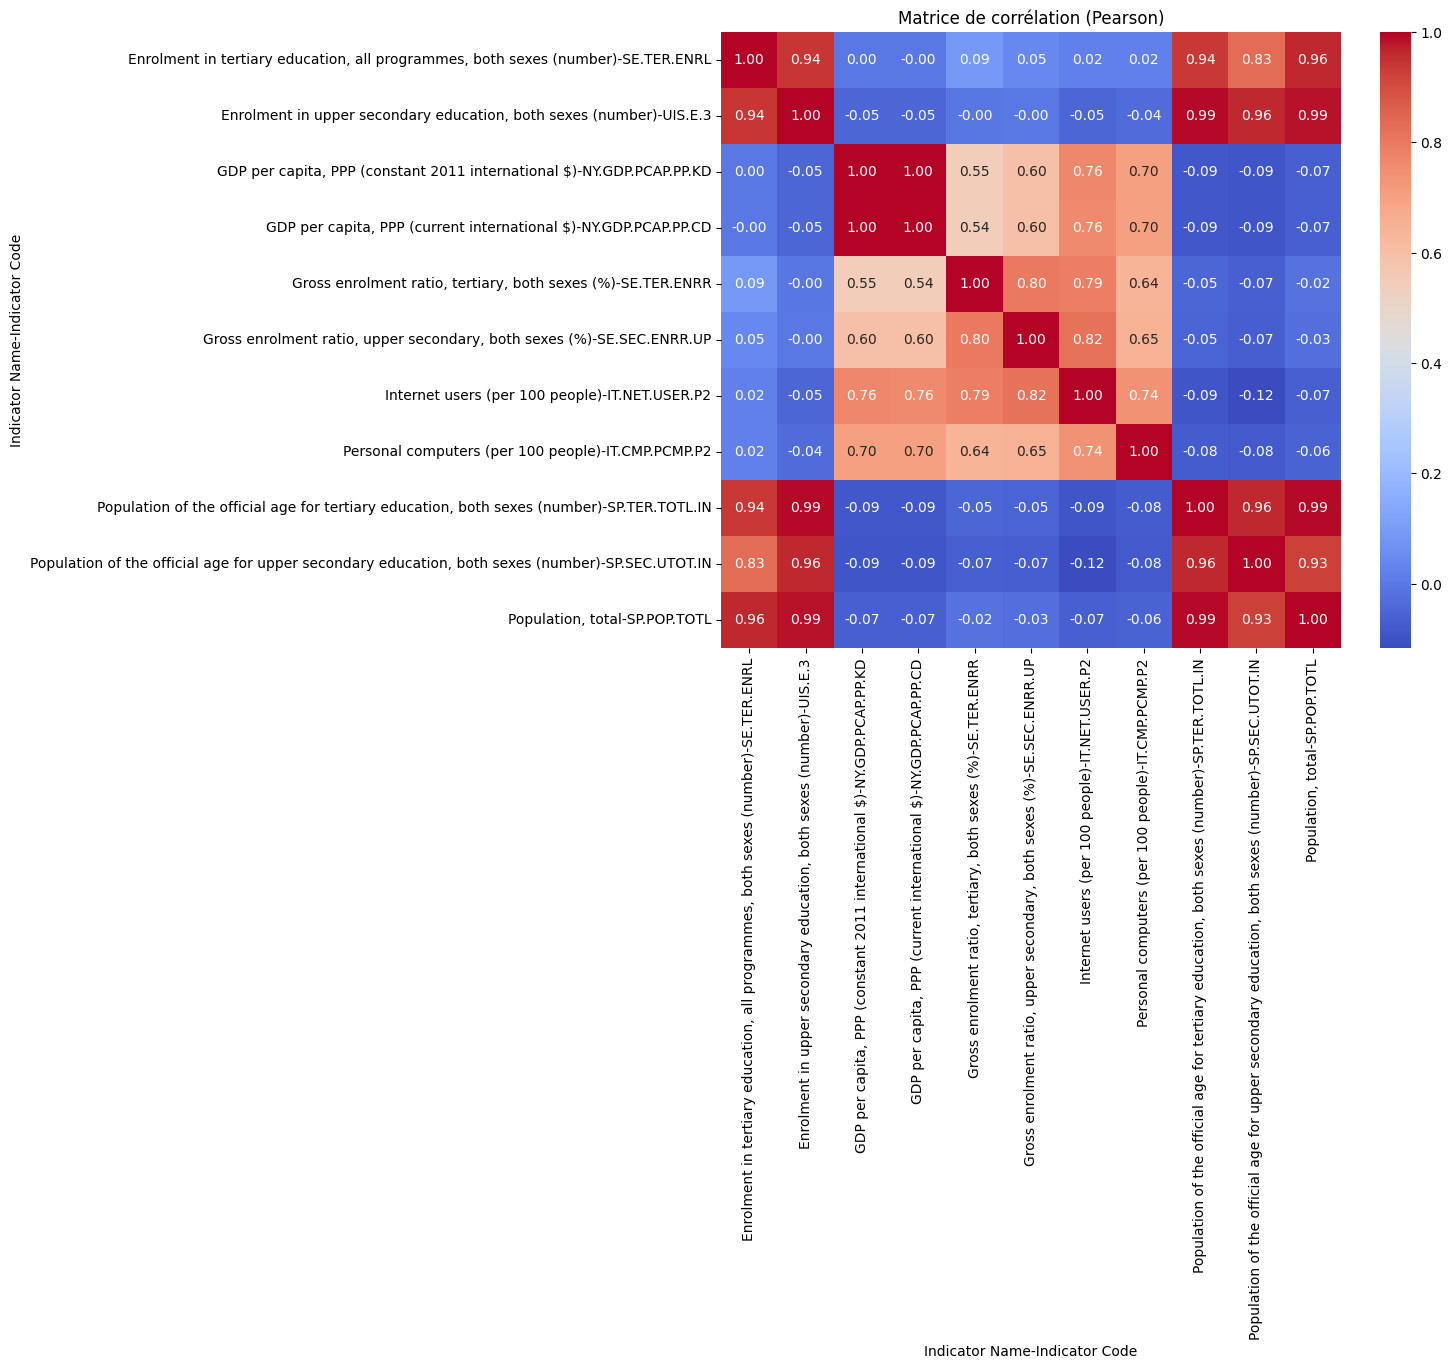

In [107]:
corr = DataExploitable.corr(method = "pearson")
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matrice de corrélation (Pearson)")
plt.show()

D'après la matrice de corrélation de Pearson on observe que certaines variables sont fortements corrélées:  
#### **Les indicateaurs concernant la popultaion cible et la population totale sont fortement corrélés:**
   - SE.TER.ENRL (Nombre d'éléève dans le etrtiaire)
   - UIS.E.3 	(Nombre d'élèves dans le secondaire suppérieur)
   - SP.TER.TOTL.IN (Nombre de personnes en âge d'être dans le tertiaire)
   - SP.SEC.UTOT.IN 	(Nombre de personne en âge d'etre dans le secondaire suppérieur)
   - SP.POP.TOTL 	(Population totale)

#### **Les indicateurs économiques sont fortement corrélés entre eux:**
   - NY.GDP.PCAP.PP.KD (PIB par habitant en parité de pouvoir d'achat en \$ constant de 2011)
   - NY.GDP.PCAP.PP.CD (PIB par habitant en parité de pouvoir d'achat en \$ courrant)

#### **les indicateurs d'infrastructure et communications sont fortement corrélés entre eux mais ils le sont également avec les indicateurs économiques précités:**
   - IT.NET.USER.P2 (Pourcentage d'utilisateurs d'internet)
   - IT.CMP.PCMP.P2 (Pourcentage d'ordinateurs personnels)

#### **Les indicateurs décrivant l'accès à l'éducation sont fortement corrélés, mais ils le sont également avec l'indicateurs donnant le pourcentages d'utilisateurs internet:**
   - SE.TER.ENRR 	(pourcentage d'élèves dans le tertiaire)
   - SE.SEC.ENRR.UP (Pourcentage d'élèves dans le secondaire suppérieur)

La méthode de Pearson pour déterminer les corrélatipon, est sensible au outliers, donc pour confiermer nos résultats, utilisons la méthode de Spearman:

In [108]:
DataExploitable.corr(method = "spearman")

,Indicator Name,"Enrolment in tertiary education, all programmes, both sexes (number)","Enrolment in upper secondary education, both sexes (number)","GDP per capita, PPP (constant 2011 international $)","GDP per capita, PPP (current international $)","Gross enrolment ratio, tertiary, both sexes (%)","Gross enrolment ratio, upper secondary, both sexes (%)",Internet users (per 100 people),Personal computers (per 100 people),"Population of the official age for tertiary education, both sexes (number)","Population of the official age for upper secondary education, both sexes (number)","Population, total"
,Indicator Code,SE.TER.ENRL,UIS.E.3,NY.GDP.PCAP.PP.KD,NY.GDP.PCAP.PP.CD,SE.TER.ENRR,SE.SEC.ENRR.UP,IT.NET.USER.P2,IT.CMP.PCMP.P2,SP.TER.TOTL.IN,SP.SEC.UTOT.IN,SP.POP.TOTL
Indicator Name,Indicator Code,,,,,,,,,,,
"Enrolment in tertiary education, all programmes, both sexes (number)",SE.TER.ENRL,1.000000,0.950217,0.191304,0.187850,0.367261,0.268199,0.206890,0.155802,0.826031,0.809070,0.865163
"Enrolment in upper secondary education, both sexes (number)",UIS.E.3,0.950217,1.000000,0.087064,0.084934,0.184514,0.167632,0.065553,0.059978,0.909231,0.911259,0.928941
"GDP per capita, PPP (constant 2011 international $)",NY.GDP.PCAP.PP.KD,0.191304,0.087064,1.000000,0.999650,0.781802,0.827232,0.919750,0.881561,-0.252142,-0.258970,-0.174982
"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,0.187850,0.084934,0.999650,1.000000,0.781233,0.827551,0.919553,0.881905,-0.256574,-0.262077,-0.178945
"Gross enrolment ratio, tertiary, both sexes (%)",SE.TER.ENRR,0.367261,0.184514,0.781802,0.781233,1.000000,0.833220,0.802580,0.762047,-0.154217,-0.172592,-0.075583
"Gross enrolment ratio, upper secondary, both sexes (%)",SE.SEC.ENRR.UP,0.268199,0.167632,0.827232,0.827551,0.833220,1.000000,0.824733,0.790167,-0.207722,-0.234385,-0.124643
Internet users (per 100 people),IT.NET.USER.P2,0.206890,0.065553,0.919750,0.919553,0.802580,0.824733,1.000000,0.888731,-0.256663,-0.276375,-0.184359
Personal computers (per 100 people),IT.CMP.PCMP.P2,0.155802,0.059978,0.881561,0.881905,0.762047,0.790167,0.888731,1.000000,-0.276269,-0.273479,-0.206309


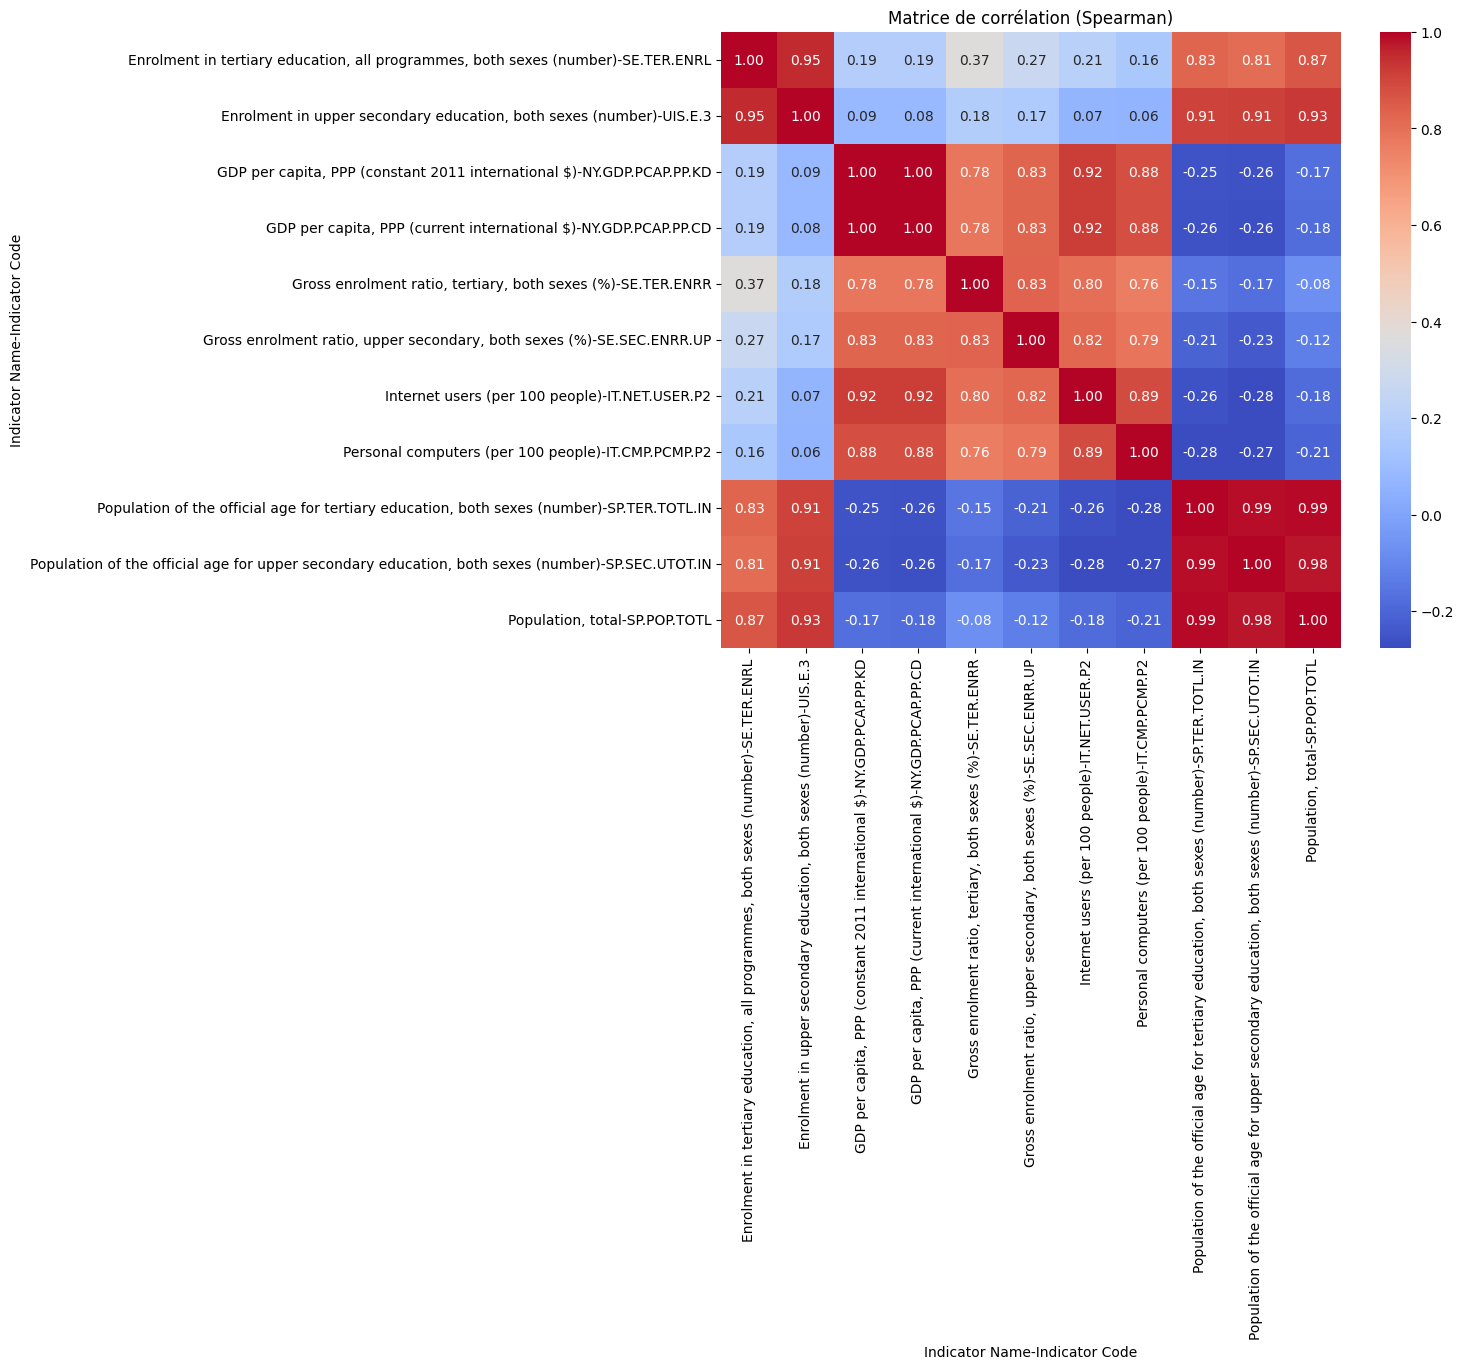

In [109]:
corr = DataExploitable.corr(method = "spearman")
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matrice de corrélation (Spearman)")
plt.show()

La matrice de correlation de Spearman, confirme nos résultats précédents.

Afin d'éviter la redondence de la même information, parmis les indicateurs corrélés nous devons en selectionner un seul qui sera porteur de l'information:
- **Indicateur économique:**  
On concervera l'indicateur **NY.GDP.PCAP.PP.CD (PIB par habitant en parité de pouvoir d'achat en $ courrant)**; Il est parfaitement remplis, le fait qu'il soit en dollar international courrant de l'année (ne tient pas compte de l'inflation sur plusieurs années) est suffisant pour comparer les pays sur une année donnée (ici en l'occurence on les compare sur la dernièe année), et il est en parité de pouvoir d'achat, ce qui permet de neutralisé les effets liés aux différences du "cout de la vie" entre les pays.

- **Indicateur d'accès à léducation:**  
On concervera l'indicateur **SE.TER.ENRR (pourcentage d'élèves dans le tertiaire)**, parce que l'accès au secondaire suppèrieur est globalement plus démocratisé à l'internantional que l'accès aux études suppérieurs. Donc le taux d'élèves dans le tertiaire sera plus restrictif que le taux d'accès au secondaire suppèrieur. De plus cette population semble plus correspondre à la population cible (bacheliers, et étudiants du suppérieur)

- **Indicateur d'infrastructure et communication:**  
On concervera l'indicateur **IT.NET.USER.P2 (Pourcentage d'utilisateurs d'internet)** qui dispose de beaucoup de donnée récentes (2016), tandis que IT.CMP.PCMP.P2 	(Pourcentage d'ordinateurs personnels) n'est plus remplis depuis 2010, et qu'on a du utiliser l'année la plus récente la mieux remplis qui se trouve être 2005, et pourrait ne plus etre repreésentatif de la situation actuelle. De plus l'accès à internet est un indicateur plus pertinent pour ce qui est de la capacité dans un pays à suivre une formation en e-learning.

- **Indicateur de population:**  
On concervera l'indicateur **SP.TER.TOTL.IN (Nombre de personnes en âge d'être dans le tertiaire)**, puisqu'il cible la poupulation concernée par notre étude contrairement à la population totale qui reste trop large. De plus SE.TER.ENRR l'indicateur d'accès à l'éducation que l'on a choisi de conserver est calculé par rapport à cet indicateur. Ce dernier nous permettra d'estimer la taile du marché potentiel pour chaque pays.

On ne tiendra pas compte des autres correlations car elles ne mesurent pas les mêmes choses:
- NY.GDP.PCAP.PP.CD mesure la "richesse" economique par habitant
- IT.NET.USER.P2 mesure l'accès à internet
- SE.TER.ENRR mesure le taux d'étudiants d'étudiants dans le supèrieur
- SP.TER.TOTL.IN mesure la taille de la population cible dans le pays

Une correlation forte n'indique pas forcément que les indicateurs décrivent la même chose, mais simplement qu'ils évoluent ensemble.

Avant de supprimer les indicateurs moins pertinent, regardons si tous ceux que l'on souhaite concervé sont bien remplis.

In [110]:
DataExploitable.notna().mean().sort_values()

Indicator Name                                                                     Indicator Code   
Enrolment in upper secondary education, both sexes (number)                        UIS.E.3              0.895833
Personal computers (per 100 people)                                                IT.CMP.PCMP.P2       0.902778
Enrolment in tertiary education, all programmes, both sexes (number)               SE.TER.ENRL          0.909722
Population of the official age for tertiary education, both sexes (number)         SP.TER.TOTL.IN       0.993056
GDP per capita, PPP (current international $)                                      NY.GDP.PCAP.PP.CD    1.000000
Gross enrolment ratio, tertiary, both sexes (%)                                    SE.TER.ENRR          1.000000
Gross enrolment ratio, upper secondary, both sexes (%)                             SE.SEC.ENRR.UP       1.000000
GDP per capita, PPP (constant 2011 international $)                                NY.GDP.PCAP.PP.KD    1.00

On constate que l'indicateur décrivant la population en age d'etre dans le tertiaire n'est pas tout a fait remplis.  
Regardons quels ont les pays concernés.

In [111]:
DataExploitable = DataExploitable.reset_index()
DataExploitable.loc[DataExploitable[('Population of the official age for tertiary education, both sexes (number)','SP.TER.TOTL.IN')].isna()]

Indicator Name,Country Name,Country Code,Region,Income Group,"Enrolment in tertiary education, all programmes, both sexes (number)","Enrolment in upper secondary education, both sexes (number)","GDP per capita, PPP (constant 2011 international $)","GDP per capita, PPP (current international $)","Gross enrolment ratio, tertiary, both sexes (%)","Gross enrolment ratio, upper secondary, both sexes (%)",Internet users (per 100 people),Personal computers (per 100 people),"Population of the official age for tertiary education, both sexes (number)","Population of the official age for upper secondary education, both sexes (number)","Population, total"
Indicator Code,,,,,SE.TER.ENRL,UIS.E.3,NY.GDP.PCAP.PP.KD,NY.GDP.PCAP.PP.CD,SE.TER.ENRR,SE.SEC.ENRR.UP,IT.NET.USER.P2,IT.CMP.PCMP.P2,SP.TER.TOTL.IN,SP.SEC.UTOT.IN,SP.POP.TOTL
136,United Arab Emirates,ARE,Middle East & North Africa,High income: nonOECD,156613.0,157821.0,67133.065519,72540.205858,43.263229,96.355492,90.600007,25.308017,NaN,244592.0,9269612.0


Il s'agit des Emirats arabes unis.

On peut estimer la valeur de l'incateur manquant à l'aide de nos autres données.  
Puisqu'on a:
$$
SE.TER.ENRR = \frac{SE.TER.ENRL}{SP.TER.TOTL.IN} \times 100
$$

In [112]:
mask = DataExploitable["Country Name"] == "United Arab Emirates"
DataExploitable.loc[mask, ('Population of the official age for tertiary education, both sexes (number)','SP.TER.TOTL.IN')] = (DataExploitable.loc[mask,('Enrolment in tertiary education, all programmes, both sexes (number)','SE.TER.ENRL')]/DataExploitable.loc[mask,('Gross enrolment ratio, tertiary, both sexes (%)', 'SE.TER.ENRR')])*100
DataExploitable.loc[mask]

Indicator Name,Country Name,Country Code,Region,Income Group,"Enrolment in tertiary education, all programmes, both sexes (number)","Enrolment in upper secondary education, both sexes (number)","GDP per capita, PPP (constant 2011 international $)","GDP per capita, PPP (current international $)","Gross enrolment ratio, tertiary, both sexes (%)","Gross enrolment ratio, upper secondary, both sexes (%)",Internet users (per 100 people),Personal computers (per 100 people),"Population of the official age for tertiary education, both sexes (number)","Population of the official age for upper secondary education, both sexes (number)","Population, total"
Indicator Code,,,,,SE.TER.ENRL,UIS.E.3,NY.GDP.PCAP.PP.KD,NY.GDP.PCAP.PP.CD,SE.TER.ENRR,SE.SEC.ENRR.UP,IT.NET.USER.P2,IT.CMP.PCMP.P2,SP.TER.TOTL.IN,SP.SEC.UTOT.IN,SP.POP.TOTL
136,United Arab Emirates,ARE,Middle East & North Africa,High income: nonOECD,156613.0,157821.0,67133.065519,72540.205858,43.263229,96.355492,90.600007,25.308017,362000.253518,244592.0,9269612.0


In [113]:
DataExploitable = DataExploitable.set_index(["Country Name", "Country Code", "Region", "Income Group"])
DataExploitable.head()

,,,Indicator Name,"Enrolment in tertiary education, all programmes, both sexes (number)","Enrolment in upper secondary education, both sexes (number)","GDP per capita, PPP (constant 2011 international $)","GDP per capita, PPP (current international $)","Gross enrolment ratio, tertiary, both sexes (%)","Gross enrolment ratio, upper secondary, both sexes (%)",Internet users (per 100 people),Personal computers (per 100 people),"Population of the official age for tertiary education, both sexes (number)","Population of the official age for upper secondary education, both sexes (number)","Population, total"
,,,Indicator Code,SE.TER.ENRL,UIS.E.3,NY.GDP.PCAP.PP.KD,NY.GDP.PCAP.PP.CD,SE.TER.ENRR,SE.SEC.ENRR.UP,IT.NET.USER.P2,IT.CMP.PCMP.P2,SP.TER.TOTL.IN,SP.SEC.UTOT.IN,SP.POP.TOTL
Country Name,Country Code,Region,Income Group,,,,,,,,,,,
Afghanistan,AFG,South Asia,Low income,262874.0,968769.0,1739.583177,1879.695509,8.662800,42.613129,10.595726,0.341903,3199607.0,2305137.0,34656032.0
Albania,ALB,Europe & Central Asia,Upper middle income,160527.0,151937.0,11359.099157,11865.501400,58.109951,89.460274,66.363445,1.689543,276247.0,149745.0,2876101.0
Algeria,DZA,Middle East & North Africa,Upper middle income,1289474.0,NaN,13921.180022,15042.442301,36.922279,62.721142,42.945527,1.030597,3492401.0,1796069.0,40606052.0
Angola,AGO,Sub-Saharan Africa,Upper middle income,221037.0,NaN,5984.640422,6466.665045,9.308020,21.098619,13.000000,0.564518,2374694.0,1736603.0,28813463.0
Antigua and Barbuda,ATG,Latin America & Caribbean,High income: nonOECD,NaN,2615.0,21013.017627,22705.482203,23.486240,82.024597,73.000000,14.655120,7935.0,3150.0,100963.0


On ne concerve que nos quatres indicateurs précités.

In [114]:
DataExploitable = DataExploitable.loc[:, DataExploitable.columns.get_level_values(1).isin(["NY.GDP.PCAP.PP.CD", "IT.NET.USER.P2", "SE.TER.ENRR", "SP.TER.TOTL.IN"])]
DataExploitable.head()

,,,Indicator Name,"GDP per capita, PPP (current international $)","Gross enrolment ratio, tertiary, both sexes (%)",Internet users (per 100 people),"Population of the official age for tertiary education, both sexes (number)"
,,,Indicator Code,NY.GDP.PCAP.PP.CD,SE.TER.ENRR,IT.NET.USER.P2,SP.TER.TOTL.IN
Country Name,Country Code,Region,Income Group,,,,
Afghanistan,AFG,South Asia,Low income,1879.695509,8.662800,10.595726,3199607.0
Albania,ALB,Europe & Central Asia,Upper middle income,11865.501400,58.109951,66.363445,276247.0
Algeria,DZA,Middle East & North Africa,Upper middle income,15042.442301,36.922279,42.945527,3492401.0
Angola,AGO,Sub-Saharan Africa,Upper middle income,6466.665045,9.308020,13.000000,2374694.0
Antigua and Barbuda,ATG,Latin America & Caribbean,High income: nonOECD,22705.482203,23.486240,73.000000,7935.0


reverifions le taux de remplissage de nos quatres indicateurs.

In [115]:
DataExploitable.notna().mean().sort_values().reset_index()

,Indicator Name,Indicator Code,0
0,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,1.0
1,"Gross enrolment ratio, tertiary, both sexes (%)",SE.TER.ENRR,1.0
2,Internet users (per 100 people),IT.NET.USER.P2,1.0
3,"Population of the official age for tertiary education, both sexes (number)",SP.TER.TOTL.IN,1.0


Ils sont parfaitement remplis.

## **Analyse**

In [116]:
DataExploitable.describe()

Indicator Name,"GDP per capita, PPP (current international $)","Gross enrolment ratio, tertiary, both sexes (%)",Internet users (per 100 people),"Population of the official age for tertiary education, both sexes (number)"
Indicator Code,NY.GDP.PCAP.PP.CD,SE.TER.ENRR,IT.NET.USER.P2,SP.TER.TOTL.IN
count,144.000000,144.000000,144.000000,1.440000e+02
mean,21765.584263,41.983285,52.973723,3.834492e+06
std,22533.438432,28.281492,27.647805,1.324114e+07
min,779.262735,0.797730,4.322758,4.409000e+03
25%,5631.934777,15.257072,27.151806,2.722795e+05
50%,14860.420274,39.610106,55.678204,9.091845e+05
75%,30140.815024,65.834103,76.560901,2.921984e+06
max,127727.965544,113.871788,98.240016,1.194700e+08


Nous allons determiner pour chaque pays la moyenne des quatres indicateurs. Mais étant donné que ces indicateurs ont des ordres de grandeur relativement différents, on normalisera chacun d'entre eux. Afin d'éviter de trop avantager les pays très peuplés, pour l'indicateur de population (SP.TER.TOTL.IN: population en âge d'être dans le tertiaire) on utilisera le logarithme avant de le normaliser.

In [117]:
colonne = ('Population of the official age for tertiary education, both sexes (number)','SP.TER.TOTL.IN')
DataExploitable.loc[:, colonne] = DataExploitable.loc[:, colonne].apply(np.log)
DataExploitable.head()

,,,Indicator Name,"GDP per capita, PPP (current international $)","Gross enrolment ratio, tertiary, both sexes (%)",Internet users (per 100 people),"Population of the official age for tertiary education, both sexes (number)"
,,,Indicator Code,NY.GDP.PCAP.PP.CD,SE.TER.ENRR,IT.NET.USER.P2,SP.TER.TOTL.IN
Country Name,Country Code,Region,Income Group,,,,
Afghanistan,AFG,South Asia,Low income,1879.695509,8.662800,10.595726,14.978539
Albania,ALB,Europe & Central Asia,Upper middle income,11865.501400,58.109951,66.363445,12.529051
Algeria,DZA,Middle East & North Africa,Upper middle income,15042.442301,36.922279,42.945527,15.066100
Angola,AGO,Sub-Saharan Africa,Upper middle income,6466.665045,9.308020,13.000000,14.680379
Antigua and Barbuda,ATG,Latin America & Caribbean,High income: nonOECD,22705.482203,23.486240,73.000000,8.979039


In [118]:
for col in DataExploitable.columns:
    if col in [('Population of the official age for tertiary education, both sexes (number)','SP.TER.TOTL.IN'), ('GDP per capita, PPP (current international $)', 'NY.GDP.PCAP.PP.CD'), ('Gross enrolment ratio, tertiary, both sexes (%)', 'SE.TER.ENRR')]:
        minimum = DataExploitable[col].min()
        maximum = DataExploitable[col].max()
        DataExploitable.loc[:,col] = (DataExploitable.loc[:,col]-minimum)/(maximum - minimum)
    else:
        DataExploitable.loc[:,col] = DataExploitable.loc[:,col]/100
DataExploitable.head()

,,,Indicator Name,"GDP per capita, PPP (current international $)","Gross enrolment ratio, tertiary, both sexes (%)",Internet users (per 100 people),"Population of the official age for tertiary education, both sexes (number)"
,,,Indicator Code,NY.GDP.PCAP.PP.CD,SE.TER.ENRR,IT.NET.USER.P2,SP.TER.TOTL.IN
Country Name,Country Code,Region,Income Group,,,,
Afghanistan,AFG,South Asia,Low income,0.008668,0.069557,0.105957,0.645344
Albania,ALB,Europe & Central Asia,Upper middle income,0.087328,0.506856,0.663634,0.405367
Algeria,DZA,Middle East & North Africa,Upper middle income,0.112354,0.319477,0.429455,0.653922
Angola,AGO,Sub-Saharan Africa,Upper middle income,0.044801,0.075263,0.130000,0.616133
Antigua and Barbuda,ATG,Latin America & Caribbean,High income: nonOECD,0.172717,0.200652,0.730000,0.057571


In [119]:
DataExploitable["moyenne"] = DataExploitable.mean(axis=1)
display(DataExploitable.sort_values(by = "moyenne", ascending = False).head(10))

,,,Indicator Name,"GDP per capita, PPP (current international $)","Gross enrolment ratio, tertiary, both sexes (%)",Internet users (per 100 people),"Population of the official age for tertiary education, both sexes (number)",moyenne
,,,Indicator Code,NY.GDP.PCAP.PP.CD,SE.TER.ENRR,IT.NET.USER.P2,SP.TER.TOTL.IN,
Country Name,Country Code,Region,Income Group,,,,,
United States,USA,North America,High income: OECD,0.447889,0.751702,0.761767,0.837582,0.699735
"Korea, Rep.",KOR,East Asia & Pacific,High income: OECD,0.275477,0.816999,0.927165,0.654340,0.668496
Australia,AUS,East Asia & Pacific,High income: OECD,0.362435,0.791594,0.882387,0.577580,0.653499
Canada,CAN,North America,High income: OECD,0.340657,0.751702,0.898400,0.616747,0.651876
Luxembourg,LUX,Europe & Central Asia,High income: OECD,0.809597,0.608032,0.974939,0.200453,0.648256
Germany,DEU,Europe & Central Asia,High income: OECD,0.378937,0.596670,0.896471,0.675706,0.636946
Norway,NOR,Europe & Central Asia,High income: OECD,0.461647,0.671230,0.972982,0.428475,0.633583
Denmark,DNK,Europe & Central Asia,High income: OECD,0.386294,0.725093,0.969678,0.436347,0.629353


<Axes: xlabel='Region', ylabel='moyenne'>

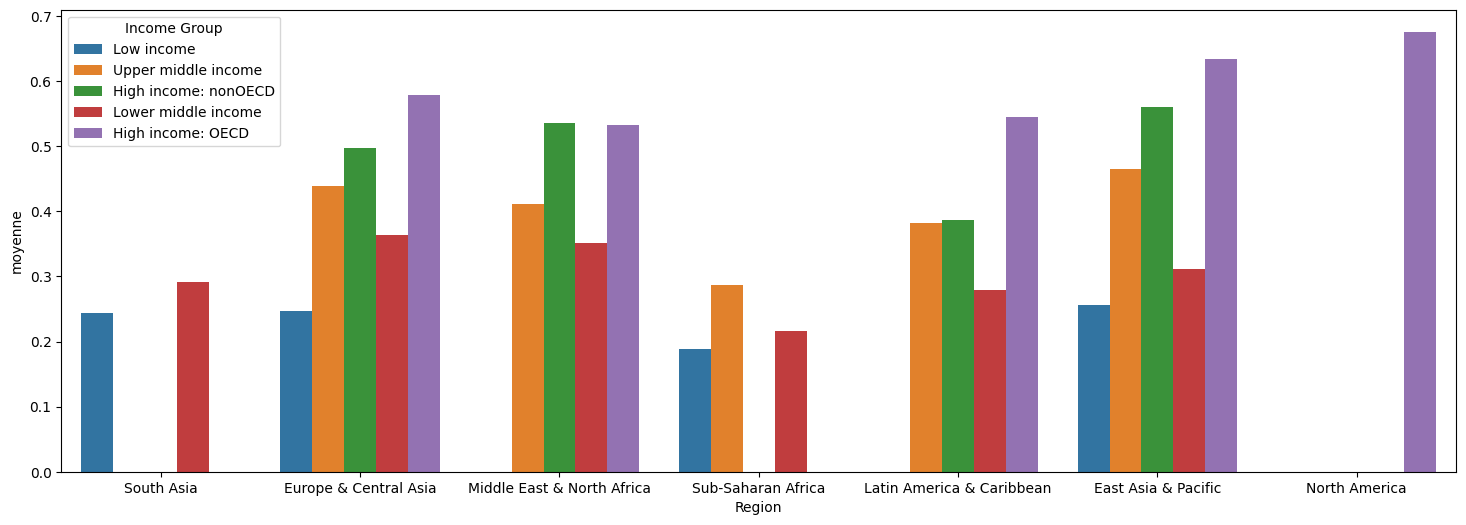

In [120]:
plt.figure(figsize=(18,6))
sns.barplot(x='Region', y='moyenne', hue='Income Group', data=DataExploitable, errorbar=None)

## **Conclusion**

D'après notre analyse, les pays ou il serait le plus judicieux d'implanter une ecole de e-learning, semblent être les pays à haut revenus, des régions nord américaine, de l'est asiatique ou d'Europe centrale.